In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the prepared insurance dataset.
df = pd.read_csv(r"C:\Users\rajab\Desktop\ML-Health-Insurance\ML-Health-Insurance\main\prepared_insurance.csv")

print("Dataset shape:", df.shape)

# Display the first few observations.
display(df.head())

Dataset shape: (162629, 42)


C:\Users\rajab\AppData\Local\Temp\ipykernel_10264\1446034401.py:7: DtypeWarning: Columns (5: date_lapse_insured, 7: date_lapse_policy) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(r"C:\Users\rajab\Desktop\ML-Health-Insurance\ML-Health-Insurance\main\prepared_insurance.csv")


,ID,ID_policy,ID_insured,period,date_effect_insured,date_lapse_insured,date_effect_policy,date_lapse_policy,year_effect_insured,year_lapse_insured,...,C_H,C_GI,C_II,C_IE_P,C_IE_S,C_IE_T,C_GE_P,C_GE_S,C_GE_T,C_C
0,1_2,1,2,2017,1993-06-15,NaN,1993-06-15,NaN,1993,NaN,...,H1,99.0,85.0,18.0,52.0,59.0,4.0,14.0,96.0,C6
1,2_1,2,1,2017,1993-06-16,NaN,1993-06-16,NaN,1993,NaN,...,H6,100.0,94.0,26.0,11.0,85.0,7.0,1.0,100.0,C6
2,3_3,3,3,2017,1993-06-15,NaN,1993-06-15,NaN,1993,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3_5,3,5,2017,1993-06-15,NaN,1993-06-15,NaN,1993,NaN,...,H6,99.0,81.0,32.0,34.0,69.0,9.0,4.0,98.0,C6
4,3_6,3,6,2017,1993-06-15,NaN,1993-06-15,NaN,1993,NaN,...,H1,32.0,9.0,100.0,80.0,2.0,83.0,51.0,19.0,C4


In [4]:
# Check column names and data types.
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("Data Type"))

# Check the number of records available in each year.
print("\nRecords by year:")
display(df["period"].value_counts().sort_index())

# Check basic dataset information.
print("\nDataset information:")
df.info()

Column names:
['ID', 'ID_policy', 'ID_insured', 'period', 'date_effect_insured', 'date_lapse_insured', 'date_effect_policy', 'date_lapse_policy', 'year_effect_insured', 'year_lapse_insured', 'year_effect_policy', 'year_lapse_policy', 'exposure_time', 'lapse', 'seniority_insured', 'seniority_policy', 'type_policy', 'type_policy_dg', 'type_product', 'reimbursement', 'new_business', 'distribution_channel', 'gender', 'age', 'premium', 'cost_claims_year', 'n_medical_services', 'n_insured_pc', 'n_insured_mun', 'n_insured_prov', 'IICIMUN', 'IICIPROV', 'C_H', 'C_GI', 'C_II', 'C_IE_P', 'C_IE_S', 'C_IE_T', 'C_GE_P', 'C_GE_S', 'C_GE_T', 'C_C']

Data types:


,Data Type
ID,str
ID_policy,int64
ID_insured,int64
period,int64
date_effect_insured,str
date_lapse_insured,str
date_effect_policy,str
date_lapse_policy,str
year_effect_insured,int64
year_lapse_insured,float64



Records by year:


period
2017    55999
2018    53555
2019    53075
Name: count, dtype: int64


Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 162629 entries, 0 to 162628
Data columns (total 42 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   ID                    162629 non-null  str    
 1   ID_policy             162629 non-null  int64  
 2   ID_insured            162629 non-null  int64  
 3   period                162629 non-null  int64  
 4   date_effect_insured   162629 non-null  str    
 5   date_lapse_insured    15099 non-null   str    
 6   date_effect_policy    162629 non-null  str    
 7   date_lapse_policy     12607 non-null   str    
 8   year_effect_insured   162629 non-null  int64  
 9   year_lapse_insured    15099 non-null   float64
 10  year_effect_policy    162629 non-null  int64  
 11  year_lapse_policy     12607 non-null   float64
 12  exposure_time         162629 non-null  float64
 13  lapse                 162629 non-null  int64  
 14  seniority_insured     162629 non-null  in

In [5]:
# Confirm that the prepared dataset has the expected structure.
print("Total observations:", len(df))
print("Total columns:", df.shape[1])

assert df.shape == (162629, 42)
assert set(df["period"].unique()) == {2017, 2018, 2019}

print("\nDataset structure verified successfully.")

Total observations: 162629
Total columns: 42

Dataset structure verified successfully.


In [6]:
# Target variable
target = "premium"

# Baseline predictors
baseline_features = [
    "exposure_time",
    "seniority_insured",
    "seniority_policy",
    "type_policy",
    "type_policy_dg",
    "type_product",
    "reimbursement",
    "distribution_channel",
    "gender",
    "age",
    "cost_claims_year",
    "n_medical_services"
]

# Additional socioeconomic and geographic predictors
additional_features = [
    "n_insured_pc",
    "n_insured_mun",
    "n_insured_prov",
    "IICIMUN",
    "IICIPROV",
    "C_H",
    "C_GI",
    "C_II",
    "C_IE_P",
    "C_IE_S",
    "C_IE_T",
    "C_GE_P",
    "C_GE_S",
    "C_GE_T",
    "C_C"
]

extended_features = baseline_features + additional_features

# Identifiers and reporting year
identifier_columns = [
    "ID", "ID_policy", "ID_insured", "period"
]

# Columns not used for prediction
excluded_features = [
    col for col in df.columns
    if col not in extended_features + identifier_columns + [target]
]

print("Target:", target)
print("Baseline predictors:", len(baseline_features))
print("Extended predictors:", len(extended_features))

print("\nExcluded columns:")
print(excluded_features)

# Verify all selected predictors exist
missing_columns = [
    col for col in extended_features + [target]
    if col not in df.columns
]

print("\nMissing required columns:", missing_columns)

Target: premium
Baseline predictors: 12
Extended predictors: 27

Excluded columns:
['date_effect_insured', 'date_lapse_insured', 'date_effect_policy', 'date_lapse_policy', 'year_effect_insured', 'year_lapse_insured', 'year_effect_policy', 'year_lapse_policy', 'lapse', 'new_business']

Missing required columns: []


In [7]:
# Identify data types among the selected predictors
numerical_features = df[extended_features].select_dtypes(
    include="number"
).columns.tolist()

categorical_features = [
    col for col in extended_features
    if col not in numerical_features
]

print("Numerical predictors:", len(numerical_features))
print(numerical_features)

print("\nCategorical predictors:", len(categorical_features))
print(categorical_features)

Numerical predictors: 19
['exposure_time', 'seniority_insured', 'seniority_policy', 'age', 'cost_claims_year', 'n_medical_services', 'n_insured_pc', 'n_insured_mun', 'n_insured_prov', 'IICIMUN', 'IICIPROV', 'C_GI', 'C_II', 'C_IE_P', 'C_IE_S', 'C_IE_T', 'C_GE_P', 'C_GE_S', 'C_GE_T']

Categorical predictors: 8
['type_policy', 'type_policy_dg', 'type_product', 'reimbursement', 'distribution_channel', 'gender', 'C_H', 'C_C']


## Duplicate Analysis

In [8]:
# Check for completely identical rows
duplicate_rows = df.duplicated().sum()

print("Total observations:", len(df))
print("Exact duplicate rows:", duplicate_rows)
print("Duplicate percentage:", round(duplicate_rows / len(df) * 100, 2), "%")

Total observations: 162629
Exact duplicate rows: 0
Duplicate percentage: 0.0 %


In [9]:
# Check how many unique identifiers are present
id_columns = ["ID", "ID_policy", "ID_insured"]

for col in id_columns:
    print(f"\n{col}")
    print("Unique values:", df[col].nunique())
    print("Repeated observations:", df[col].duplicated().sum())


ID
Unique values: 65161
Repeated observations: 97468

ID_policy
Unique values: 31392
Repeated observations: 131237

ID_insured
Unique values: 273
Repeated observations: 162356


In [10]:
# Check identifier repetitions within the same reporting year
for col in id_columns:
    repeated = df.duplicated(subset=["period", col]).sum()

    print(f"{col} repeated within the same year: {repeated}")

ID repeated within the same year: 0
ID_policy repeated within the same year: 81800
ID_insured repeated within the same year: 162075


In [11]:
# A policy may contain multiple insured members.
# Check whether the same insured member appears repeatedly
# under the same policy in the same reporting year.

key_columns = ["period", "ID_policy", "ID_insured"]

duplicate_keys = df.duplicated(
    subset=key_columns,
    keep=False
)

print("Rows with repeated policy-insured-year combinations:",
      duplicate_keys.sum())

# Display examples if repetitions exist
if duplicate_keys.any():
    display(
        df.loc[duplicate_keys, key_columns]
        .sort_values(key_columns)
        .head(20)
    )

Rows with repeated policy-insured-year combinations: 0


In [12]:
# Check columns that contain only one unique value.
unique_counts = df.nunique(dropna=True)

constant_columns = unique_counts[unique_counts <= 1]

print("Constant or all-missing columns:")
display(constant_columns)

Constant or all-missing columns:


lapse           1
new_business    1
dtype: int64

In [13]:
# Summarize the numerical columns.
numerical_summary = df.select_dtypes(include="number").describe().T

display(numerical_summary)

,count,mean,std,min,25%,50%,75%,max
ID_policy,162629.0,17464.990863,10540.362249,1.00,8236.0000,16967.0000,26162.00,38909.00
ID_insured,162629.0,2.949259,8.961875,1.00,1.0000,2.0000,3.00,289.00
period,162629.0,2017.982020,0.818763,2017.00,2017.0000,2018.0000,2019.00,2019.00
year_effect_insured,162629.0,2002.056798,13.058793,1933.00,1994.0000,2004.0000,2013.00,2018.00
year_lapse_insured,15099.0,2018.665607,0.471793,2018.00,2018.0000,2019.0000,2019.00,2019.00
year_effect_policy,162629.0,2000.994306,14.045146,1932.00,1994.0000,2003.0000,2012.00,2018.00
year_lapse_policy,12607.0,2018.665107,0.471972,2018.00,2018.0000,2019.0000,2019.00,2019.00
exposure_time,162629.0,0.991158,0.093617,0.00,1.0000,1.0000,1.00,1.00
lapse,162629.0,2.000000,0.000000,2.00,2.0000,2.0000,2.00,2.00
seniority_insured,162629.0,15.925222,13.036371,1.00,5.0000,14.0000,23.00,86.00


In [14]:
# Count negative and zero values in numerical predictors and target.
numeric_columns = df[extended_features + [target]].select_dtypes(
    include="number"
).columns

value_check = pd.DataFrame({
    "Negative Values": (df[numeric_columns] < 0).sum(),
    "Zero Values": (df[numeric_columns] == 0).sum()
})

display(value_check)

,Negative Values,Zero Values
exposure_time,0,1438
seniority_insured,0,0
seniority_policy,0,0
age,0,528
cost_claims_year,0,33681
n_medical_services,0,33681
n_insured_pc,0,0
n_insured_mun,0,0
n_insured_prov,0,0
IICIMUN,0,0


In [15]:
# Display the unique categories in each categorical predictor.
for col in categorical_features:
    print(f"\n{col}")
    print(df[col].value_counts(dropna=False))


type_policy
type_policy
I    98565
C    64064
Name: count, dtype: int64

type_policy_dg
type_policy_dg
I     77180
C3    45205
SE    21385
C1    15230
C2     3625
C4        4
Name: count, dtype: int64

type_product
type_product
S    129701
P     23523
D      7108
I      2297
Name: count, dtype: int64

reimbursement
reimbursement
No     138174
Yes     24455
Name: count, dtype: int64

distribution_channel
distribution_channel
I    107742
A     54791
D        96
Name: count, dtype: int64

gender
gender
F    89055
M    73574
Name: count, dtype: int64

C_H
C_H
H6     98786
H3     18869
H2     14581
H5     11531
H4     10722
NaN     6188
H1      1952
Name: count, dtype: int64

C_C
C_C
C3     77057
C6     37823
C1     17283
C4     15937
NaN     5937
C5      4331
C2      4261
Name: count, dtype: int64


In [16]:
## Active-Policy Eligibility and Year-wise Records

In [17]:
# Check the number of observations in each reporting year.
year_counts = df["period"].value_counts().sort_index()

print("Observations by year:")
display(year_counts.to_frame("Observations"))

# Check the eligibility conditions.
print("\nLapse values:")
display(df["lapse"].value_counts(dropna=False))

print("\nNew business values:")
display(df["new_business"].value_counts(dropna=False))

# Verify eligibility independently for each year.
eligibility_check = df.groupby("period").agg(
    total_records=("ID", "size"),
    valid_lapse=("lapse", lambda x: (x == 2).sum()),
    existing_policies=("new_business", lambda x: (x == "No").sum())
)

display(eligibility_check)

# Confirm that every observation satisfies both conditions.
eligible = (df["lapse"] == 2) & (df["new_business"] == "No")

print("\nEligible observations:", eligible.sum())
print("Ineligible observations:", (~eligible).sum())

Observations by year:


,Observations
period,
2017,55999
2018,53555
2019,53075



Lapse values:


lapse
2    162629
Name: count, dtype: int64


New business values:


new_business
No    162629
Name: count, dtype: int64

,total_records,valid_lapse,existing_policies
period,,,
2017,55999,55999,55999
2018,53555,53555,53555
2019,53075,53075,53075



Eligible observations: 162629
Ineligible observations: 0


In [18]:
# Summarize the main data-quality checks.
quality_summary = pd.DataFrame({
    "Check": [
        "Total observations",
        "Total columns",
        "Exact duplicate rows",
        "Missing target values",
        "Zero or negative premiums",
        "Constant columns",
        "Baseline predictors",
        "Extended predictors"
    ],
    "Result": [
        len(df),
        df.shape[1],
        df.duplicated().sum(),
        df[target].isna().sum(),
        (df[target] <= 0).sum(),
        ", ".join(df.columns[df.nunique(dropna=True) <= 1]),
        len(baseline_features),
        len(extended_features)
    ]
})

display(quality_summary)

,Check,Result
0,Total observations,162629
1,Total columns,42
2,Exact duplicate rows,0
3,Missing target values,0
4,Zero or negative premiums,0
5,Constant columns,"lapse, new_business"
6,Baseline predictors,12
7,Extended predictors,27


In [19]:
# Check that all selected predictors exist in the dataset.
feature_check = pd.DataFrame({
    "Feature": extended_features,
    "Data Type": df[extended_features].dtypes.astype(str).values,
    "Missing Values": df[extended_features].isna().sum().values,
    "Missing (%)": (
        df[extended_features].isna().mean() * 100
    ).round(2).values
})

display(feature_check)

,Feature,Data Type,Missing Values,Missing (%)
0,exposure_time,float64,0,0.00
1,seniority_insured,int64,0,0.00
2,seniority_policy,int64,0,0.00
3,type_policy,str,0,0.00
4,type_policy_dg,str,0,0.00
5,type_product,str,0,0.00
6,reimbursement,str,0,0.00
7,distribution_channel,str,0,0.00
8,gender,str,0,0.00
9,age,int64,0,0.00


In [20]:
# Verify that all records satisfy the eligibility criteria.
eligible = (df["lapse"] == 2) & (df["new_business"] == "No")

print("Eligible records:", eligible.sum())
print("Ineligible records:", (~eligible).sum())

# Check that identifiers and excluded variables are not predictors.
excluded_in_model = set(extended_features) & set(
    identifier_columns + excluded_features
)

print("\nExcluded variables accidentally selected:", excluded_in_model)

print("\nBaseline features:", len(baseline_features))
print("Extended features:", len(extended_features))

Eligible records: 162629
Ineligible records: 0

Excluded variables accidentally selected: set()

Baseline features: 12
Extended features: 27


In [21]:
## Missing VAlue Analysis

In [22]:
# Calculate missingness across all 42 columns.
total_cells = df.size
missing_cells = df.isna().sum().sum()

print("Complete dataset")
print("Total cells:", total_cells)
print("Missing cells:", missing_cells)
print("Missing percentage:", round(missing_cells / total_cells * 100, 2), "%")


# Calculate missingness across the 25 selected predictors.
X = df[extended_features]

total_predictor_cells = X.size
missing_predictor_cells = X.isna().sum().sum()

print("\nSelected predictors")
print("Total cells:", total_predictor_cells)
print("Missing cells:", missing_predictor_cells)
print("Missing percentage:",
      round(missing_predictor_cells / total_predictor_cells * 100, 2), "%")

Complete dataset
Total cells: 6830418
Missing cells: 680777
Missing percentage: 9.97 %

Selected predictors
Total cells: 4390983
Missing cells: 85673
Missing percentage: 1.95 %


In [23]:
# Calculate missing counts and percentages for every predictor.
missing_summary = pd.DataFrame({
    "Missing Count": X.isna().sum(),
    "Missing (%)": (X.isna().mean() * 100).round(2)
})

missing_summary = missing_summary.sort_values(
    "Missing (%)", ascending=False
)

display(missing_summary)

,Missing Count,Missing (%)
C_GE_S,8172,5.02
C_GE_T,8172,5.02
C_GI,8172,5.02
C_II,8172,5.02
C_IE_P,8172,5.02
C_IE_S,8172,5.02
C_IE_T,8172,5.02
C_GE_P,8172,5.02
IICIMUN,6188,3.80
C_H,6188,3.80


In [24]:
# Separate predictors based on missingness.
complete_features = missing_summary[
    missing_summary["Missing Count"] == 0
].index.tolist()

incomplete_features = missing_summary[
    missing_summary["Missing Count"] > 0
].index.tolist()

print("Complete predictors:", len(complete_features))
print(complete_features)

print("\nIncomplete predictors:", len(incomplete_features))
print(incomplete_features)


# Count observations affected by missing predictors.
rows_with_missing = X.isna().any(axis=1).sum()

print("\nObservations with at least one missing predictor:",
      rows_with_missing)

print("Percentage of observations affected:",
      round(rows_with_missing / len(X) * 100, 2), "%")

Complete predictors: 15
['cost_claims_year', 'gender', 'age', 'reimbursement', 'type_product', 'type_policy_dg', 'type_policy', 'seniority_policy', 'seniority_insured', 'exposure_time', 'distribution_channel', 'n_medical_services', 'n_insured_pc', 'n_insured_mun', 'n_insured_prov']

Incomplete predictors: 12
['C_GE_S', 'C_GE_T', 'C_GI', 'C_II', 'C_IE_P', 'C_IE_S', 'C_IE_T', 'C_GE_P', 'IICIMUN', 'C_H', 'C_C', 'IICIPROV']

Observations with at least one missing predictor: 8221
Percentage of observations affected: 5.06 %


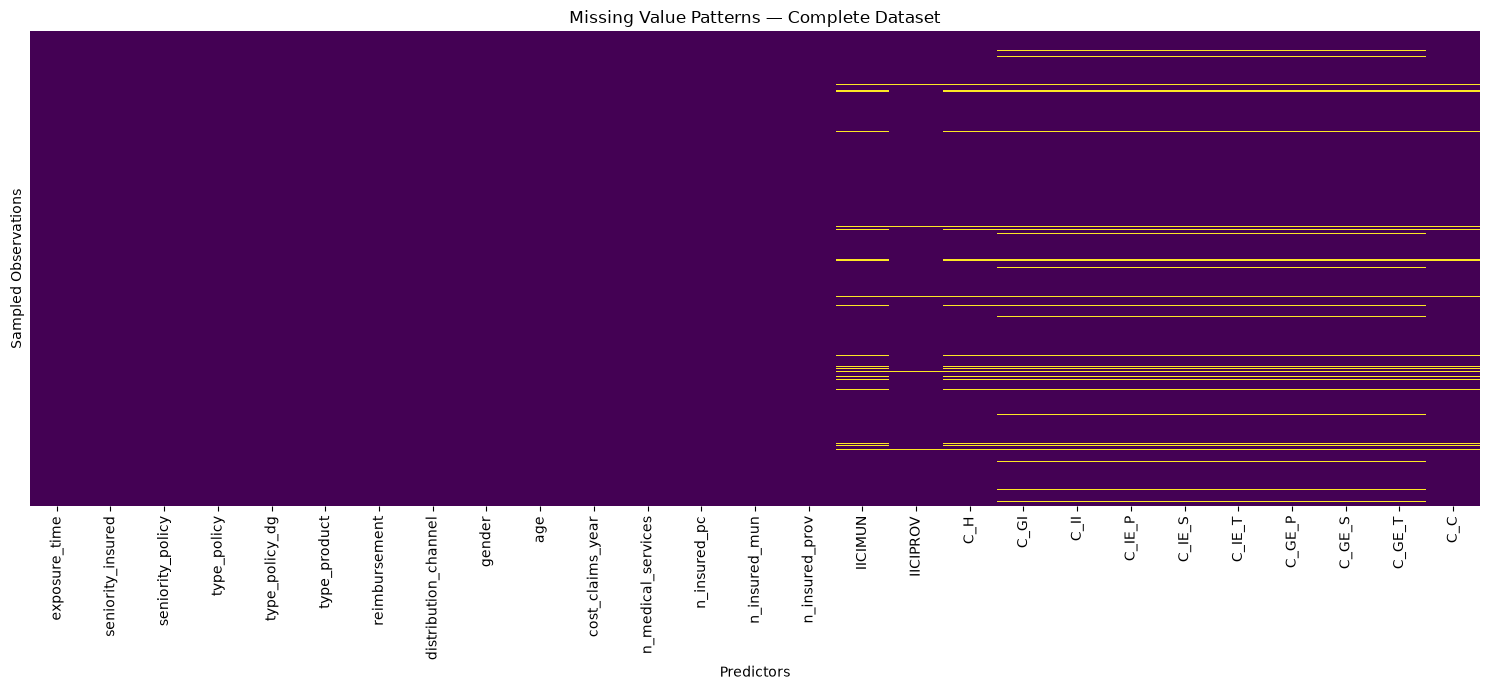

In [25]:
# Sample observations from the complete dataset.
missing_sample = df.sample(
    n=min(5000, len(df)),
    random_state=42
)

plt.figure(figsize=(15, 7))

sns.heatmap(
    missing_sample[extended_features].isna(),
    cmap="viridis",
    cbar=False,
    yticklabels=False
)

plt.title("Missing Value Patterns — Complete Dataset")
plt.xlabel("Predictors")
plt.ylabel("Sampled Observations")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

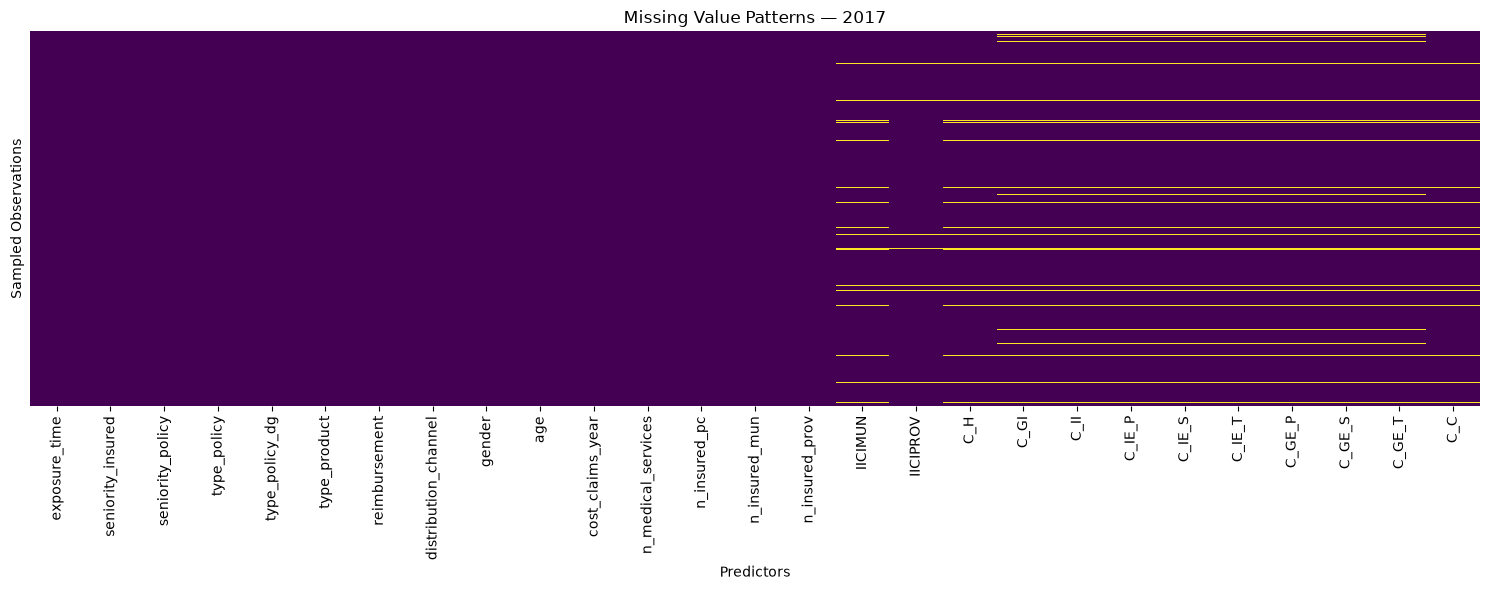

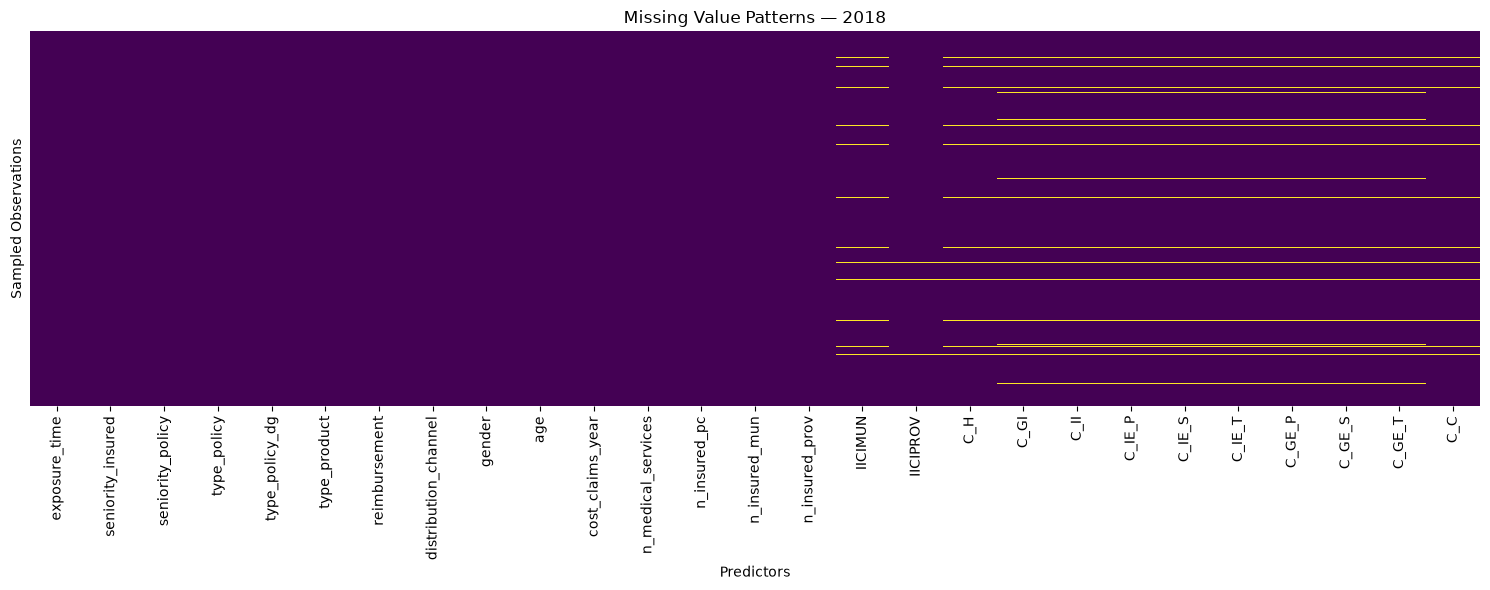

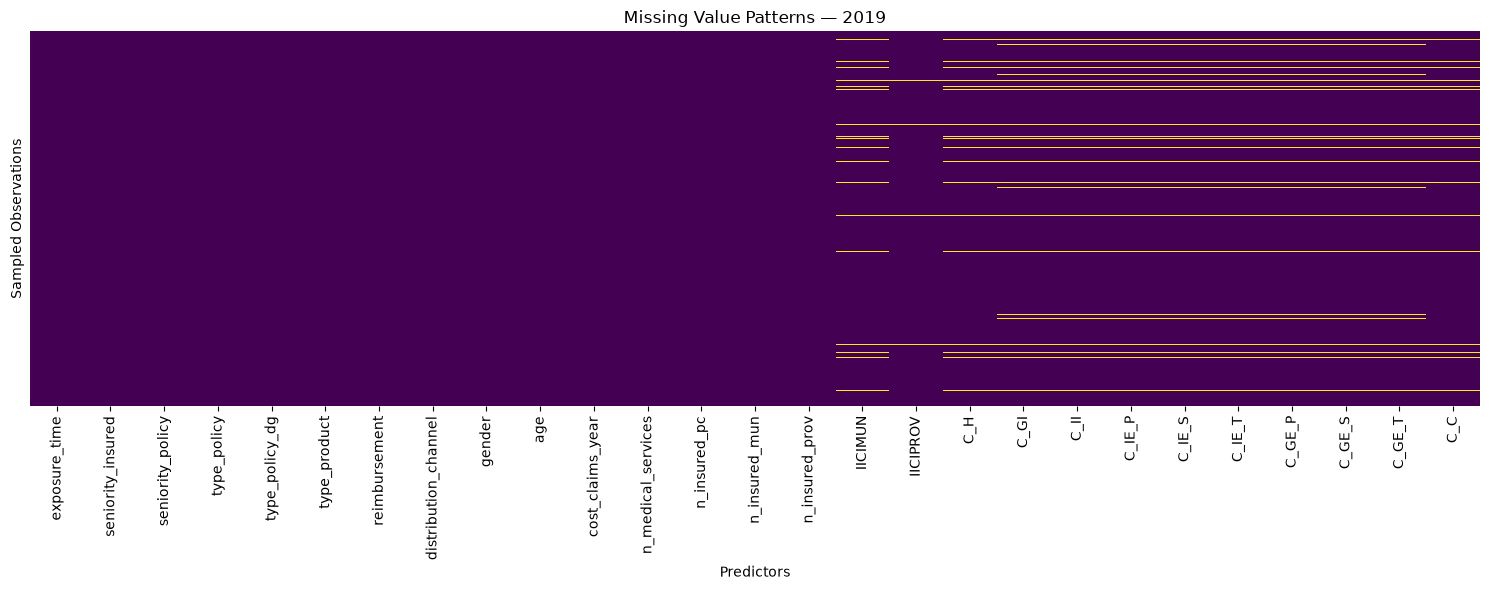

In [26]:
# Compare missing-value patterns across reporting years.
for year in sorted(df["period"].unique()):

    year_data = df[df["period"] == year]

    year_sample = year_data.sample(
        n=min(3000, len(year_data)),
        random_state=42
    )

    plt.figure(figsize=(15, 6))

    sns.heatmap(
        year_sample[extended_features].isna(),
        cmap="viridis",
        cbar=False,
        yticklabels=False
    )

    plt.title(f"Missing Value Patterns — {year}")
    plt.xlabel("Predictors")
    plt.ylabel("Sampled Observations")
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()

In [27]:
# Select predictors that contain missing values.
missing_features = X.columns[X.isna().any()].tolist()

missing_flags = X[missing_features].isna()

# Group predictors with exactly the same missingness pattern.
pattern_groups = []
checked = set()

for col in missing_features:

    if col in checked:
        continue

    group = []

    for other in missing_features:
        if missing_flags[col].equals(missing_flags[other]):
            group.append(other)

    pattern_groups.append(group)
    checked.update(group)

print("Identical missingness groups:\n")

for i, group in enumerate(pattern_groups, 1):
    print(f"Group {i}: {group}")

Identical missingness groups:

Group 1: ['IICIMUN', 'C_H']
Group 2: ['IICIPROV']
Group 3: ['C_GI', 'C_II', 'C_IE_P', 'C_IE_S', 'C_IE_T', 'C_GE_P', 'C_GE_S', 'C_GE_T']
Group 4: ['C_C']


In [28]:
# Calculate pairwise missingness overlap through jaccard similarity
missing_binary = missing_flags.astype(int)

intersection = missing_binary.T.dot(missing_binary)

missing_counts = missing_binary.sum()

union = (
    missing_counts.values[:, None]
    + missing_counts.values[None, :]
    - intersection
)

overlap = intersection / union

display(overlap.round(3))

,IICIMUN,IICIPROV,C_H,C_GI,C_II,C_IE_P,C_IE_S,C_IE_T,C_GE_P,C_GE_S,C_GE_T,C_C
IICIMUN,1.000,0.321,1.000,0.754,0.754,0.754,0.754,0.754,0.754,0.754,0.754,0.946
IICIPROV,0.321,1.000,0.321,0.243,0.243,0.243,0.243,0.243,0.243,0.243,0.243,0.334
C_H,1.000,0.321,1.000,0.754,0.754,0.754,0.754,0.754,0.754,0.754,0.754,0.946
C_GI,0.754,0.243,0.754,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,0.716
C_II,0.754,0.243,0.754,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,0.716
C_IE_P,0.754,0.243,0.754,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,0.716
C_IE_S,0.754,0.243,0.754,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,0.716
C_IE_T,0.754,0.243,0.754,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,0.716
C_GE_P,0.754,0.243,0.754,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,0.716
C_GE_S,0.754,0.243,0.754,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,0.716


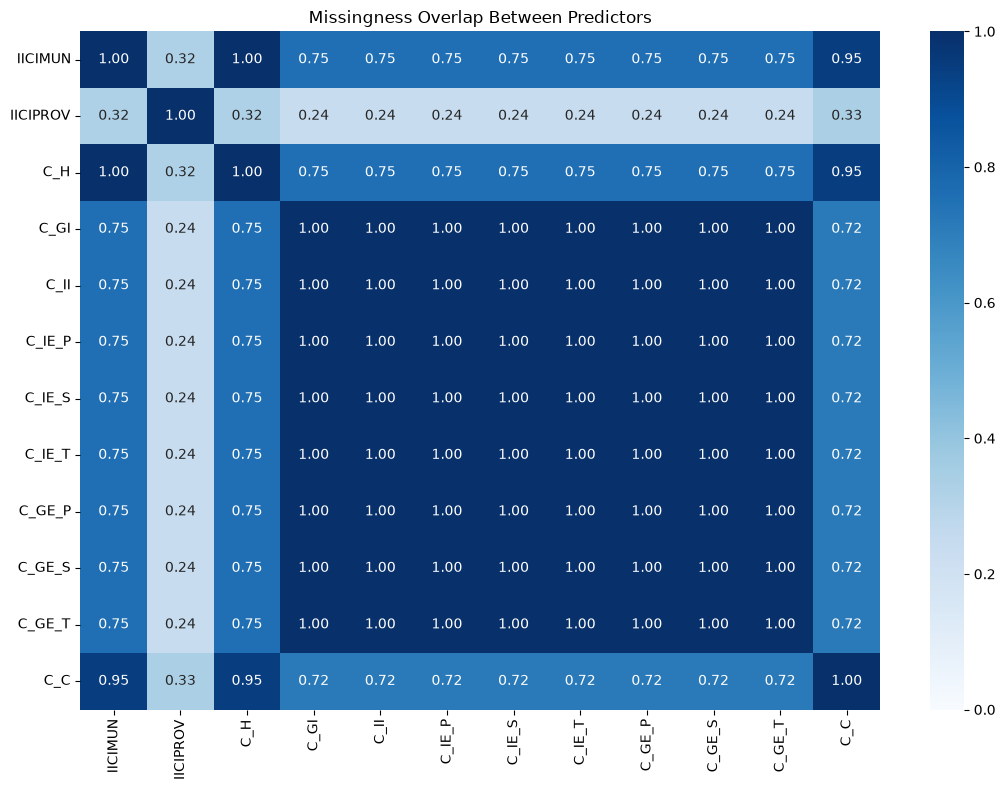

In [29]:
plt.figure(figsize=(11, 8))

sns.heatmap(
    overlap,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=0,
    vmax=1
)

plt.title("Missingness Overlap Between Predictors")
plt.tight_layout()
plt.show()

In [30]:
## Missingness pattern analysis

In [31]:
from scipy.stats import chi2_contingency

# Four unique missingness patterns
missing_groups = {
    "IICIMUN / C_H": "IICIMUN",
    "IICIPROV": "IICIPROV",
    "Eight C indicators": "C_GI",
    "C_C": "C_C"
}

# Candidate observed predictors
observed_features = [
    "type_policy",
    "type_policy_dg",
    "type_product",
    "reimbursement",
    "distribution_channel",
    "gender",
    "period"
]

results = []

for group_name, missing_col in missing_groups.items():

    for feature in observed_features:

        table = pd.crosstab(
            df[feature],
            df[missing_col].isna()
        )

        # Remove very rare categories for more reliable comparisons
        table = table.loc[table.sum(axis=1) >= 30]

        if table.shape[0] < 2 or table.shape[1] < 2:
            continue

        chi2, p_value, _, expected = chi2_contingency(table)

        n = table.to_numpy().sum()
        cramers_v = np.sqrt(
            chi2 / (n * (min(table.shape) - 1))
        )

        results.append({
            "Missingness Group": group_name,
            "Observed Feature": feature,
            "P-value": p_value,
            "Cramers V": cramers_v
        })

association_results = pd.DataFrame(results)

# Display every association, not just the strongest
display(
    association_results.sort_values(
        ["Missingness Group", "Cramers V"],
        ascending=[True, False]
    ).round(4)
)

,Missingness Group,Observed Feature,P-value,Cramers V
22,C_C,type_policy_dg,0.0000,0.1509
21,C_C,type_policy,0.0000,0.0926
23,C_C,type_product,0.0000,0.0814
24,C_C,reimbursement,0.0000,0.0723
26,C_C,gender,0.0000,0.0316
25,C_C,distribution_channel,0.0000,0.0314
27,C_C,period,0.2479,0.0041
15,Eight C indicators,type_policy_dg,0.0000,0.1606
14,Eight C indicators,type_policy,0.0000,0.1030
16,Eight C indicators,type_product,0.0000,0.0603


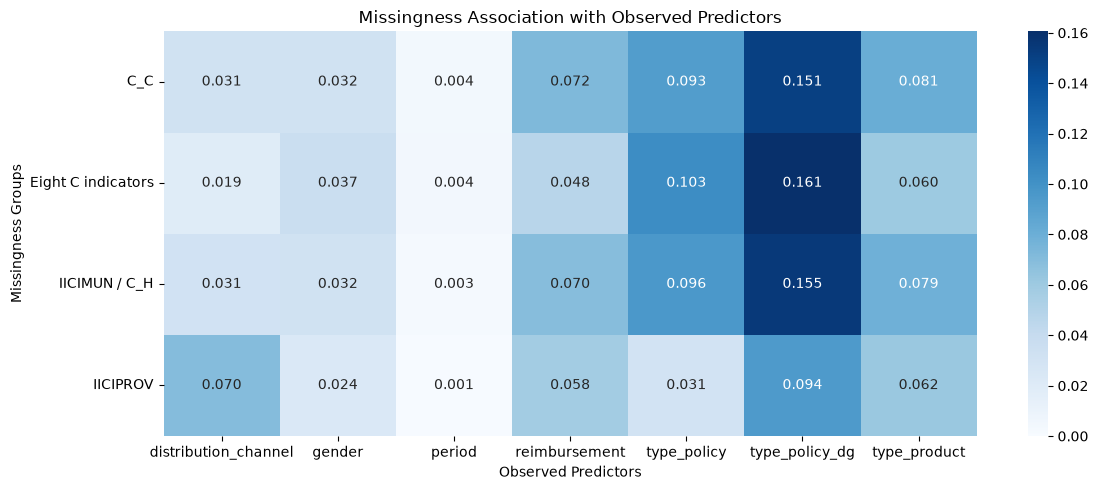

In [32]:
association_matrix = association_results.pivot(
    index="Missingness Group",
    columns="Observed Feature",
    values="Cramers V"
)

plt.figure(figsize=(12, 5))

sns.heatmap(
    association_matrix,
    annot=True,
    fmt=".3f",
    cmap="Blues",
    vmin=0
)

plt.title("Missingness Association with Observed Predictors")
plt.xlabel("Observed Predictors")
plt.ylabel("Missingness Groups")
plt.tight_layout()
plt.show()

In [33]:
# Rank observed predictors by association strength
ranked_results = association_results.sort_values(
    ["Missingness Group", "Cramers V"],
    ascending=[True, False]
)

# Show the top three predictors for each missingness group
top_predictors = ranked_results.groupby(
    "Missingness Group"
).head(3)

display(top_predictors.round(4))

,Missingness Group,Observed Feature,P-value,Cramers V
22,C_C,type_policy_dg,0.0,0.1509
21,C_C,type_policy,0.0,0.0926
23,C_C,type_product,0.0,0.0814
15,Eight C indicators,type_policy_dg,0.0,0.1606
14,Eight C indicators,type_policy,0.0,0.1030
16,Eight C indicators,type_product,0.0,0.0603
1,IICIMUN / C_H,type_policy_dg,0.0,0.1549
0,IICIMUN / C_H,type_policy,0.0,0.0956
2,IICIMUN / C_H,type_product,0.0,0.0790
8,IICIPROV,type_policy_dg,0.0,0.0941


In [34]:
## Strongest association for each group found to be with type_policy_dg	
# Missingness is associated with observed policy characteristics
# Observed policy subtype helps explain missingness
# this gives evidence against the MCAR , so KNN imputation would be preferable though we dont have proof for MAR and MNAR but it is plausible 

## Univariate Numerical Analysis

In [35]:
numerical_features = (
    df[extended_features]
    .select_dtypes(include="number")
    .columns
    .difference(
        ["ID", "ID_policy", "ID_insured", "period", "premium"],
        sort=False
    )
    .tolist()
)

print("Total numerical predictors:", len(numerical_features))

display(
    pd.DataFrame({
        "Numerical Feature": numerical_features,
        "Data Type": df[numerical_features].dtypes.astype(str).values
    })
)

Total numerical predictors: 19


,Numerical Feature,Data Type
0,exposure_time,float64
1,seniority_insured,int64
2,seniority_policy,int64
3,age,int64
4,cost_claims_year,float64
5,n_medical_services,int64
6,n_insured_pc,int64
7,n_insured_mun,int64
8,n_insured_prov,int64
9,IICIMUN,float64


In [36]:
descriptive_stats = df[numerical_features].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
).T

descriptive_stats = descriptive_stats.rename(
    columns={"50%": "median"}
)

descriptive_stats["missing"] = df[numerical_features].isna().sum()

display(descriptive_stats.round(2))

,count,mean,std,min,1%,5%,25%,median,75%,95%,99%,max,missing
exposure_time,162629.0,0.99,0.09,0.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,0
seniority_insured,162629.0,15.93,13.04,1.00,1.00,1.00,5.00,14.00,23.00,41.00,59.00,86.00,0
seniority_policy,162629.0,16.99,14.02,1.00,1.00,1.00,6.00,15.00,24.00,44.00,67.00,87.00,0
age,162629.0,48.40,22.78,0.00,2.00,7.00,33.00,50.00,66.00,82.00,89.00,99.00,0
cost_claims_year,162629.0,672.15,1702.16,0.00,0.00,0.00,45.07,247.47,637.50,2642.04,7198.57,78035.10,0
n_medical_services,162629.0,19.45,29.76,0.00,0.00,0.00,1.00,8.00,27.00,73.00,127.00,3094.00,0
n_insured_pc,162629.0,280.59,353.18,1.00,2.00,7.00,49.00,125.00,415.00,941.00,1150.00,2518.00,0
n_insured_mun,162629.0,6159.68,7835.43,1.00,2.00,11.00,113.00,1521.00,17303.00,19315.00,19315.00,19315.00,0
n_insured_prov,162629.0,14304.16,12032.97,4.00,121.00,421.00,3398.00,7475.00,28298.00,29465.00,29465.00,29465.00,0
IICIMUN,156441.0,7.38,6.52,0.01,0.24,0.67,1.85,7.38,11.10,16.39,22.84,263.16,6188


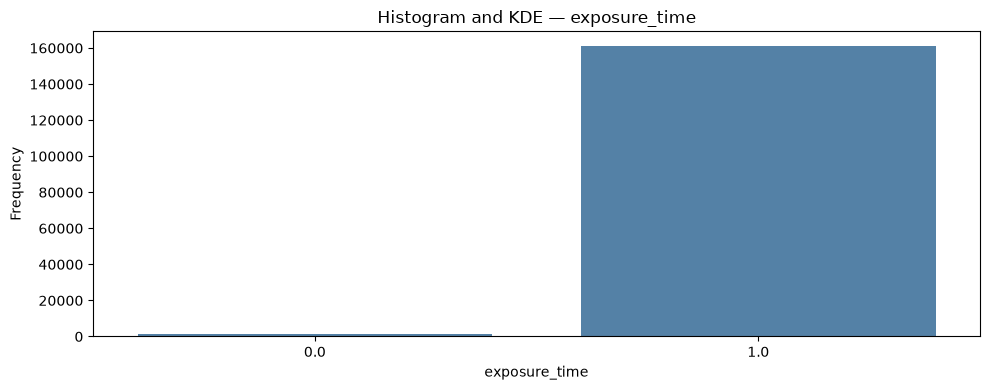

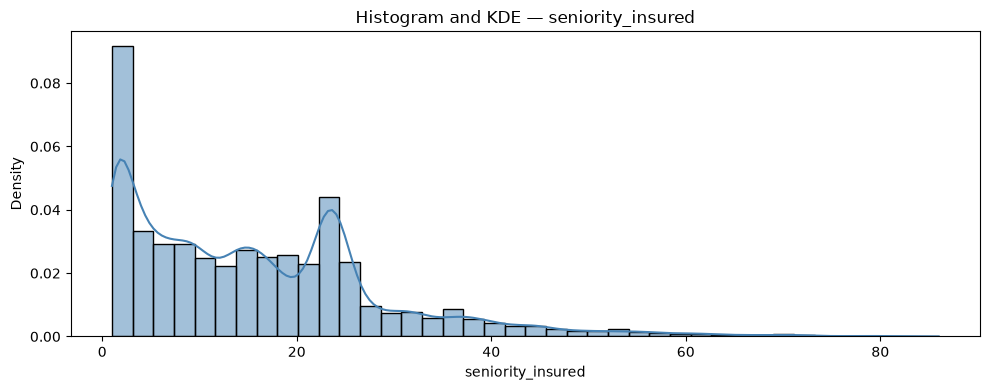

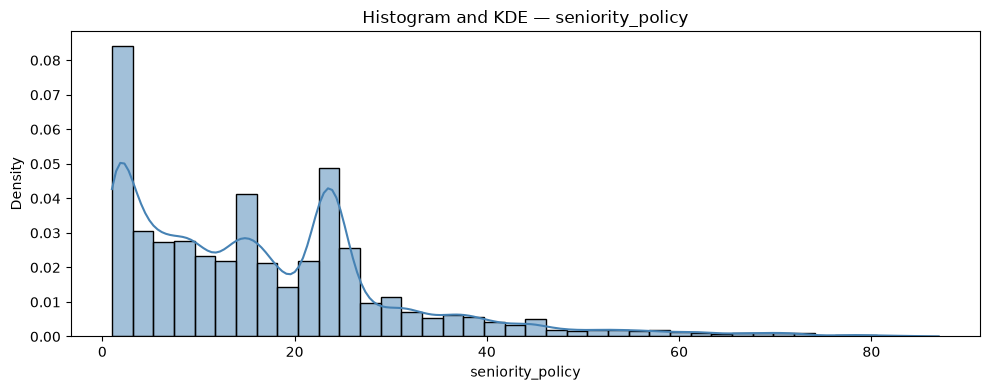

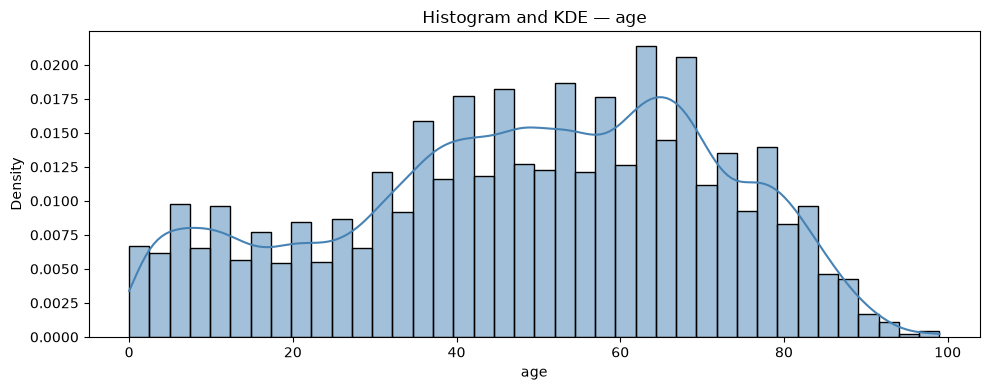

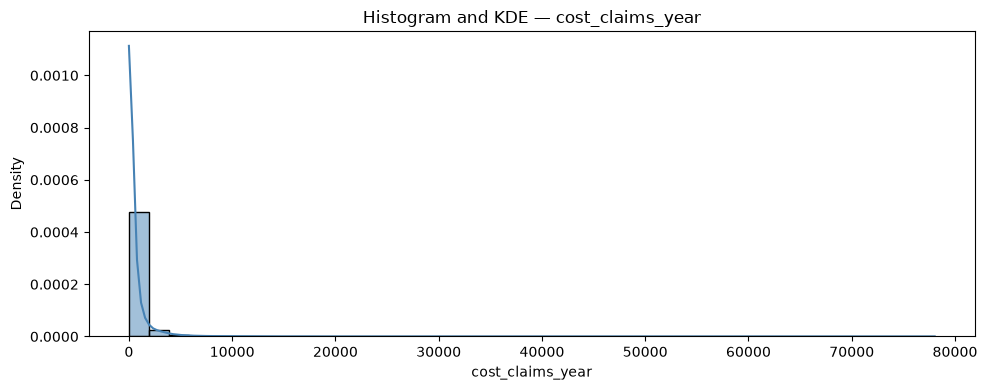

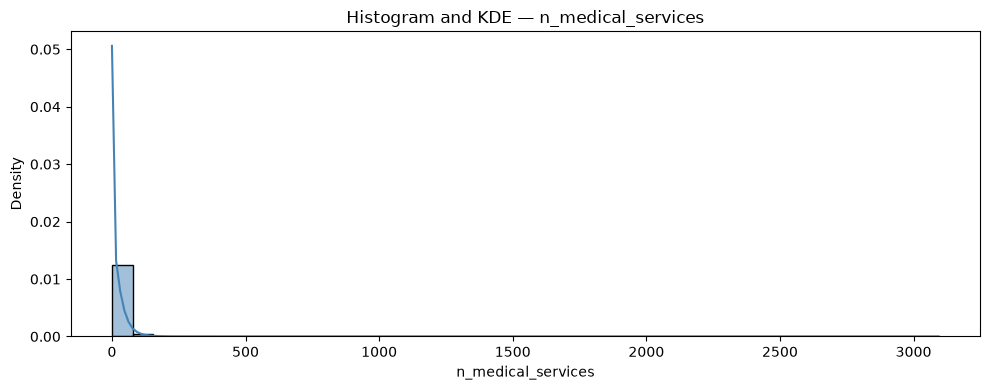

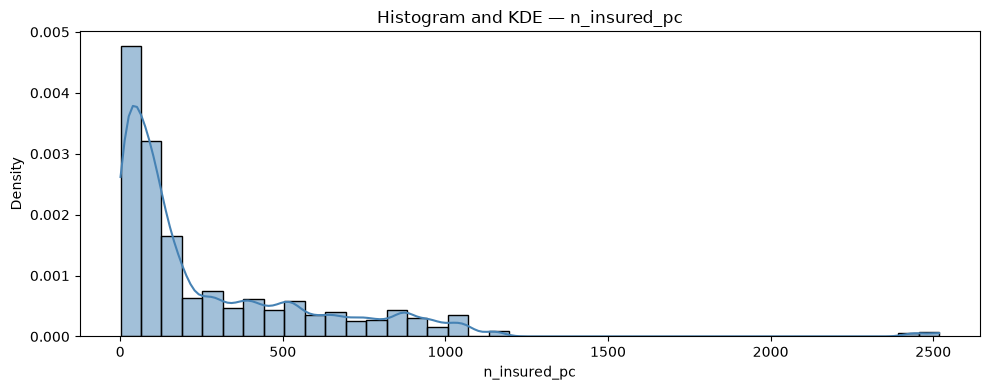

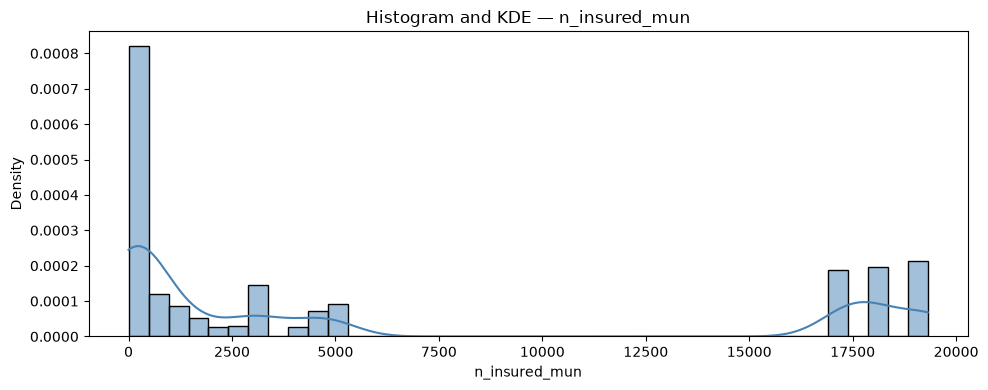

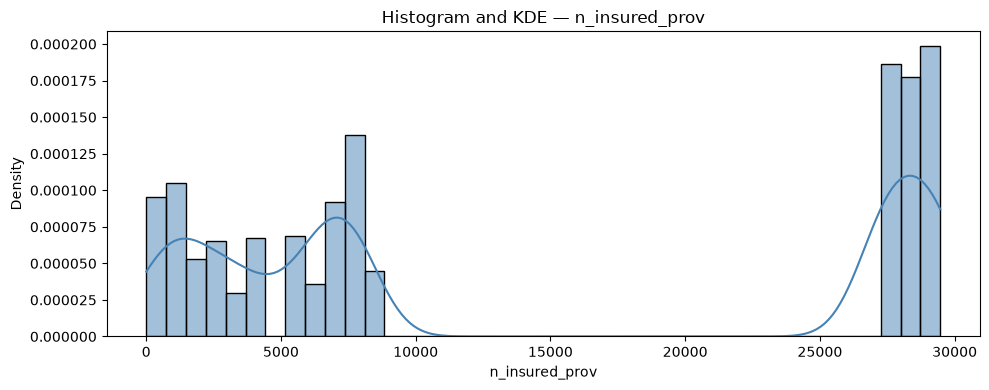

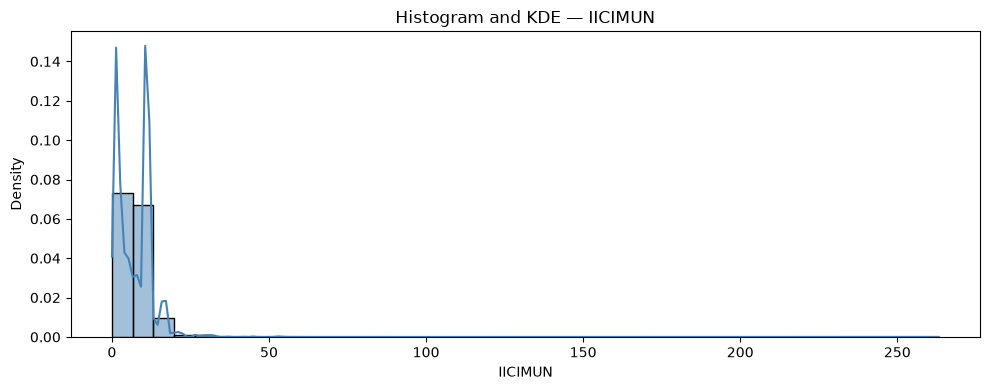

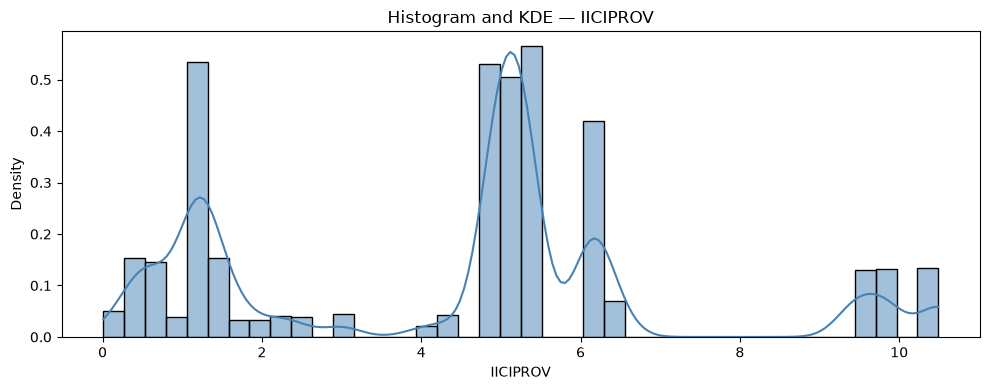

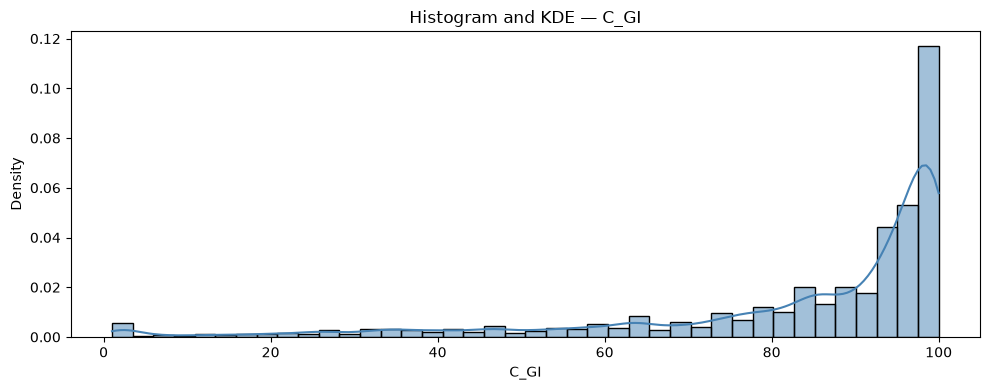

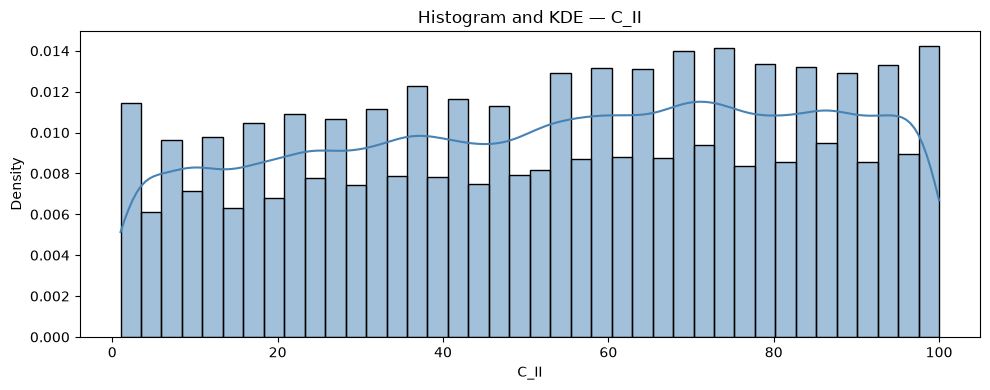

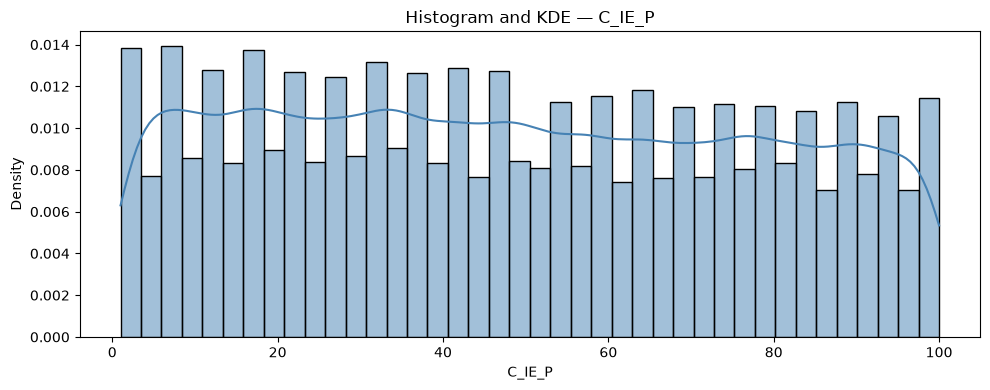

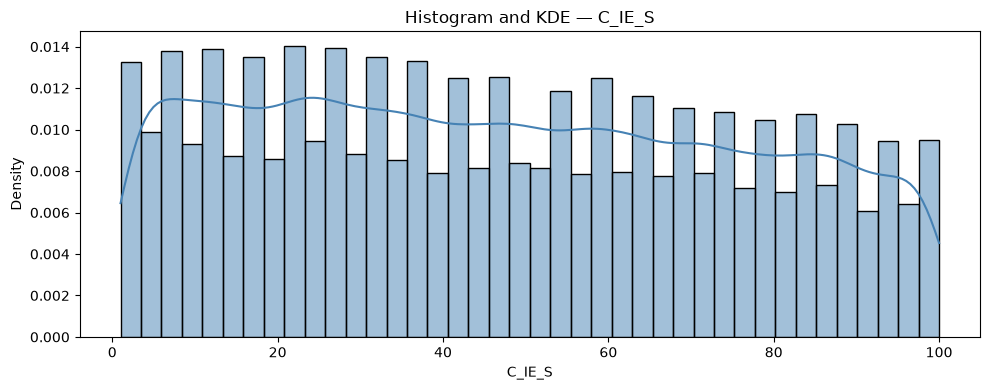

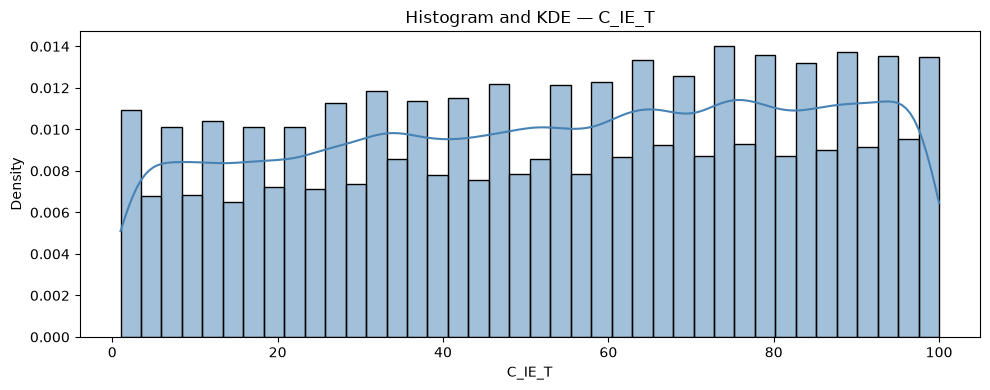

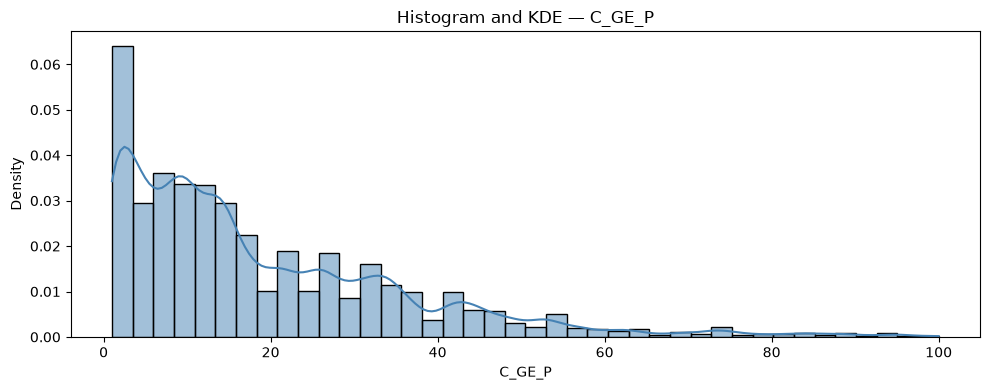

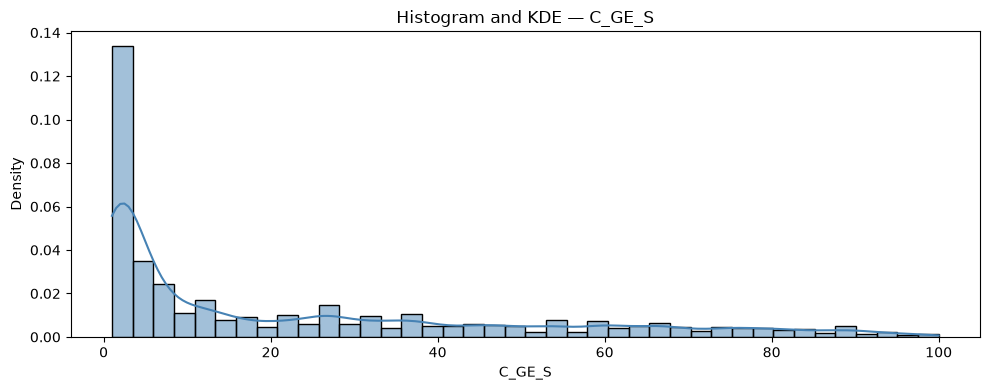

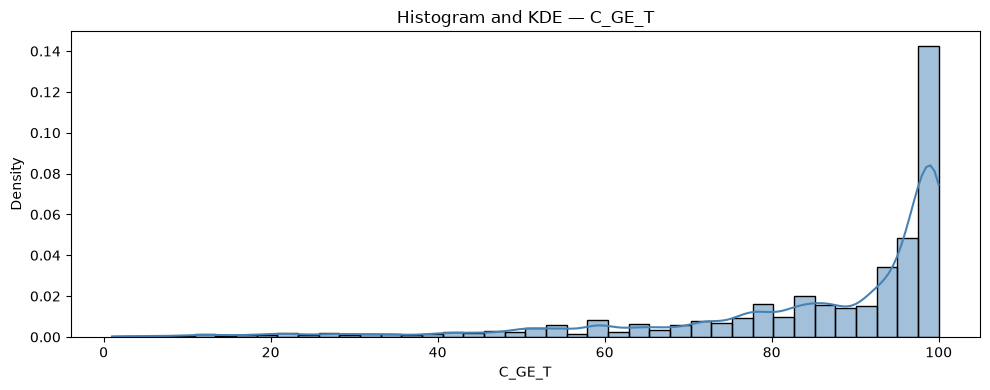

In [37]:
for col in numerical_features:

    values = df[col].dropna()

    plt.figure(figsize=(10, 4))

    if col == "exposure_time":
        sns.countplot(x=values, color="steelblue")
        plt.ylabel("Frequency")
    else:
        sns.histplot(
            values,
            bins=40,
            kde=True,
            stat="density",
            color="steelblue"
        )
        plt.ylabel("Density")

    plt.title(f"Histogram and KDE — {col}")
    plt.xlabel(col)

    plt.tight_layout()
    plt.show()

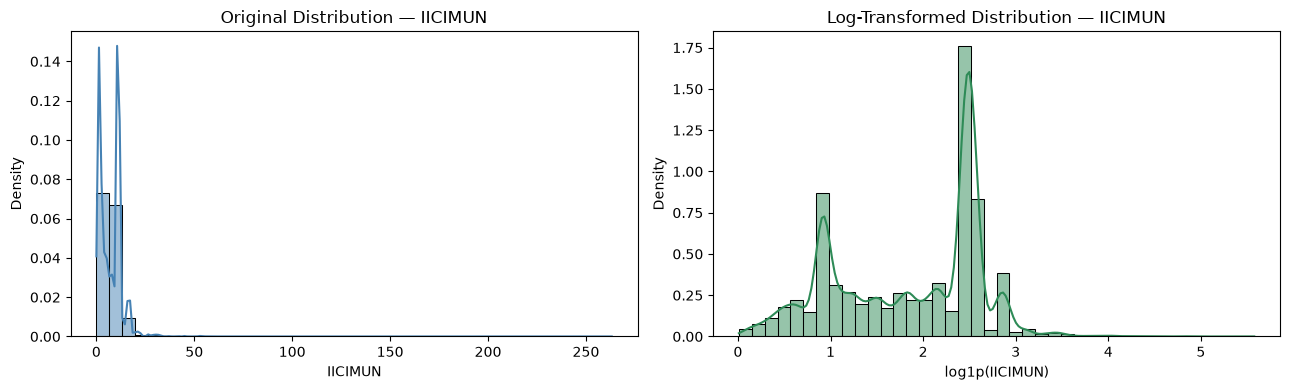

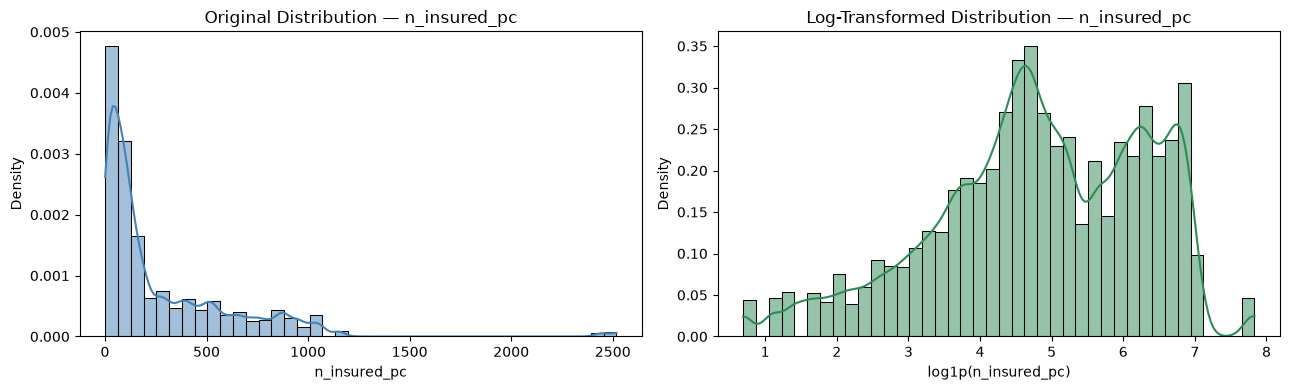

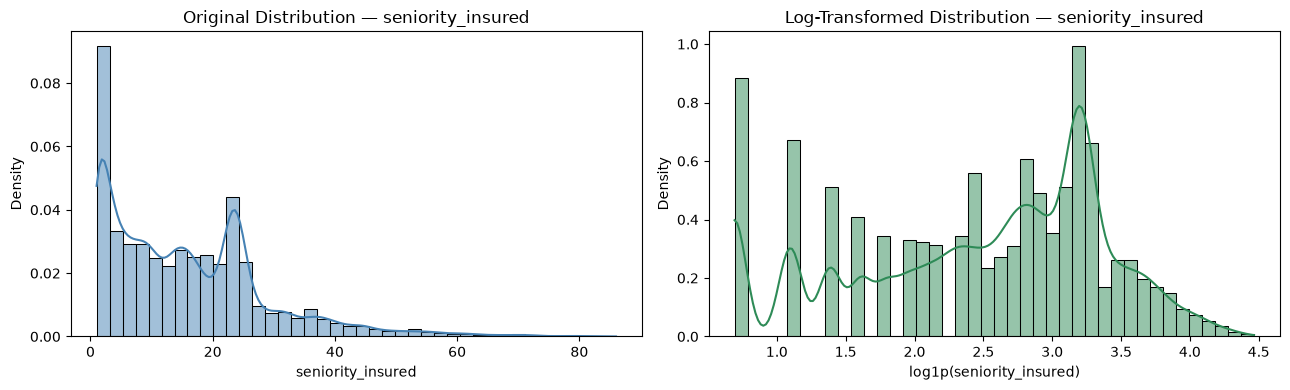

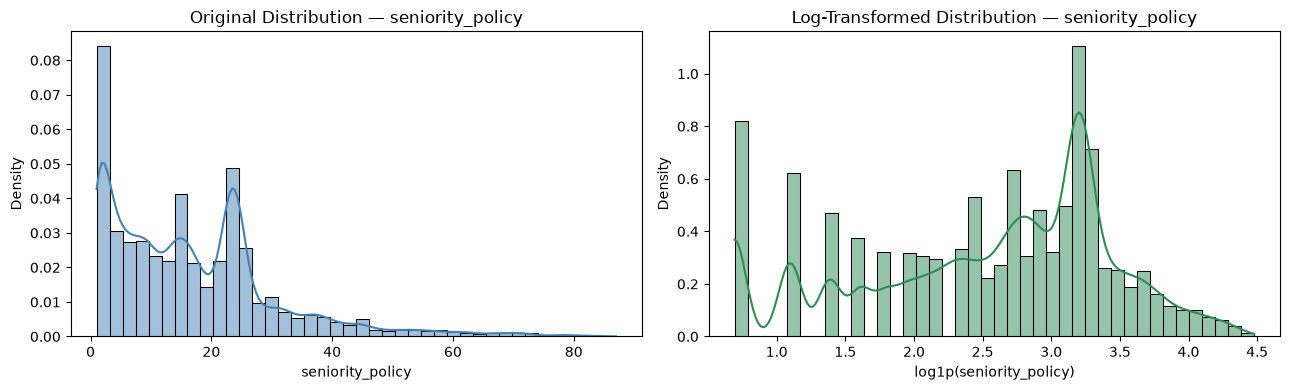

In [38]:
log_candidates = [
    "IICIMUN",
    "n_insured_pc",
    "seniority_insured",
    "seniority_policy"
]

for col in log_candidates:

    original = df[col].dropna()
    transformed = np.log1p(original)

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    sns.histplot(
        original,
        bins=40,
        kde=True,
        stat="density",
        color="steelblue",
        ax=axes[0]
    )

    axes[0].set_title(f"Original Distribution — {col}")
    axes[0].set_xlabel(col)

    sns.histplot(
        transformed,
        bins=40,
        kde=True,
        stat="density",
        color="seagreen",
        ax=axes[1]
    )

    axes[1].set_title(f"Log-Transformed Distribution — {col}")
    axes[1].set_xlabel(f"log1p({col})")

    plt.tight_layout()
    plt.show()

In [39]:
comparison = []

for col in log_candidates:

    original = df[col].dropna()
    transformed = np.log1p(original)

    comparison.append({
        "Feature": col,
        "Original Skewness": original.skew(),
        "Log Skewness": transformed.skew(),
        "Original Kurtosis": original.kurt(),
        "Log Kurtosis": transformed.kurt()
    })

comparison_df = pd.DataFrame(comparison)

display(comparison_df.round(3))

,Feature,Original Skewness,Log Skewness,Original Kurtosis,Log Kurtosis
0,IICIMUN,7.419,-0.336,203.640,-0.988
1,n_insured_pc,2.610,-0.488,10.928,-0.214
2,seniority_insured,1.218,-0.473,1.975,-0.782
3,seniority_policy,1.351,-0.507,2.479,-0.668


## Categorical Feature Analysis

In [40]:
categorical_features = [
    "type_policy",
    "type_policy_dg",
    "type_product",
    "reimbursement",
    "distribution_channel",
    "gender",
    "C_H",
    "C_C"
]

for col in categorical_features:
    print(f"\n{'=' * 50}")
    print(f"Feature: {col}")
    print(f"Data type: {df[col].dtype}")
    print(f"Unique categories: {df[col].nunique(dropna=True)}")
    print(f"Missing values: {df[col].isna().sum()}")
    print(f"Categories: {df[col].drop_duplicates().tolist()}")


Feature: type_policy
Data type: str
Unique categories: 2
Missing values: 0
Categories: ['I', 'C']

Feature: type_policy_dg
Data type: str
Unique categories: 6
Missing values: 0
Categories: ['I', 'C1', 'C2', 'SE', 'C3', 'C4']

Feature: type_product
Data type: str
Unique categories: 4
Missing values: 0
Categories: ['S', 'P', 'I', 'D']

Feature: reimbursement
Data type: str
Unique categories: 2
Missing values: 0
Categories: ['No', 'Yes']

Feature: distribution_channel
Data type: str
Unique categories: 3
Missing values: 0
Categories: ['A', 'I', 'D']

Feature: gender
Data type: str
Unique categories: 2
Missing values: 0
Categories: ['F', 'M']

Feature: C_H
Data type: str
Unique categories: 6
Missing values: 6188
Categories: ['H1', 'H6', nan, 'H2', 'H3', 'H5', 'H4']

Feature: C_C
Data type: str
Unique categories: 6
Missing values: 5937
Categories: ['C6', nan, 'C4', 'C3', 'C5', 'C1', 'C2']


In [41]:
for col in categorical_features:
    counts = df[col].value_counts(dropna=False)
    percentages = df[col].value_counts(
        normalize=True, dropna=False
    ) * 100

    frequency_table = pd.DataFrame({
        "Count": counts,
        "Percentage (%)": percentages.round(2)
    })

    print(f"\n{'=' * 50}")
    print(f"Feature: {col}")
    display(frequency_table)


Feature: type_policy


,Count,Percentage (%)
type_policy,,
I,98565,60.61
C,64064,39.39



Feature: type_policy_dg


,Count,Percentage (%)
type_policy_dg,,
I,77180,47.46
C3,45205,27.80
SE,21385,13.15
C1,15230,9.36
C2,3625,2.23
C4,4,0.00



Feature: type_product


,Count,Percentage (%)
type_product,,
S,129701,79.75
P,23523,14.46
D,7108,4.37
I,2297,1.41


... (6 outputs left out)


Feature: C_H


,Count,Percentage (%)
C_H,,
H6,98786,60.74
H3,18869,11.60
H2,14581,8.97
H5,11531,7.09
H4,10722,6.59
NaN,6188,3.80
H1,1952,1.20



Feature: C_C


,Count,Percentage (%)
C_C,,
C3,77057,47.38
C6,37823,23.26
C1,17283,10.63
C4,15937,9.80
NaN,5937,3.65
C5,4331,2.66
C2,4261,2.62


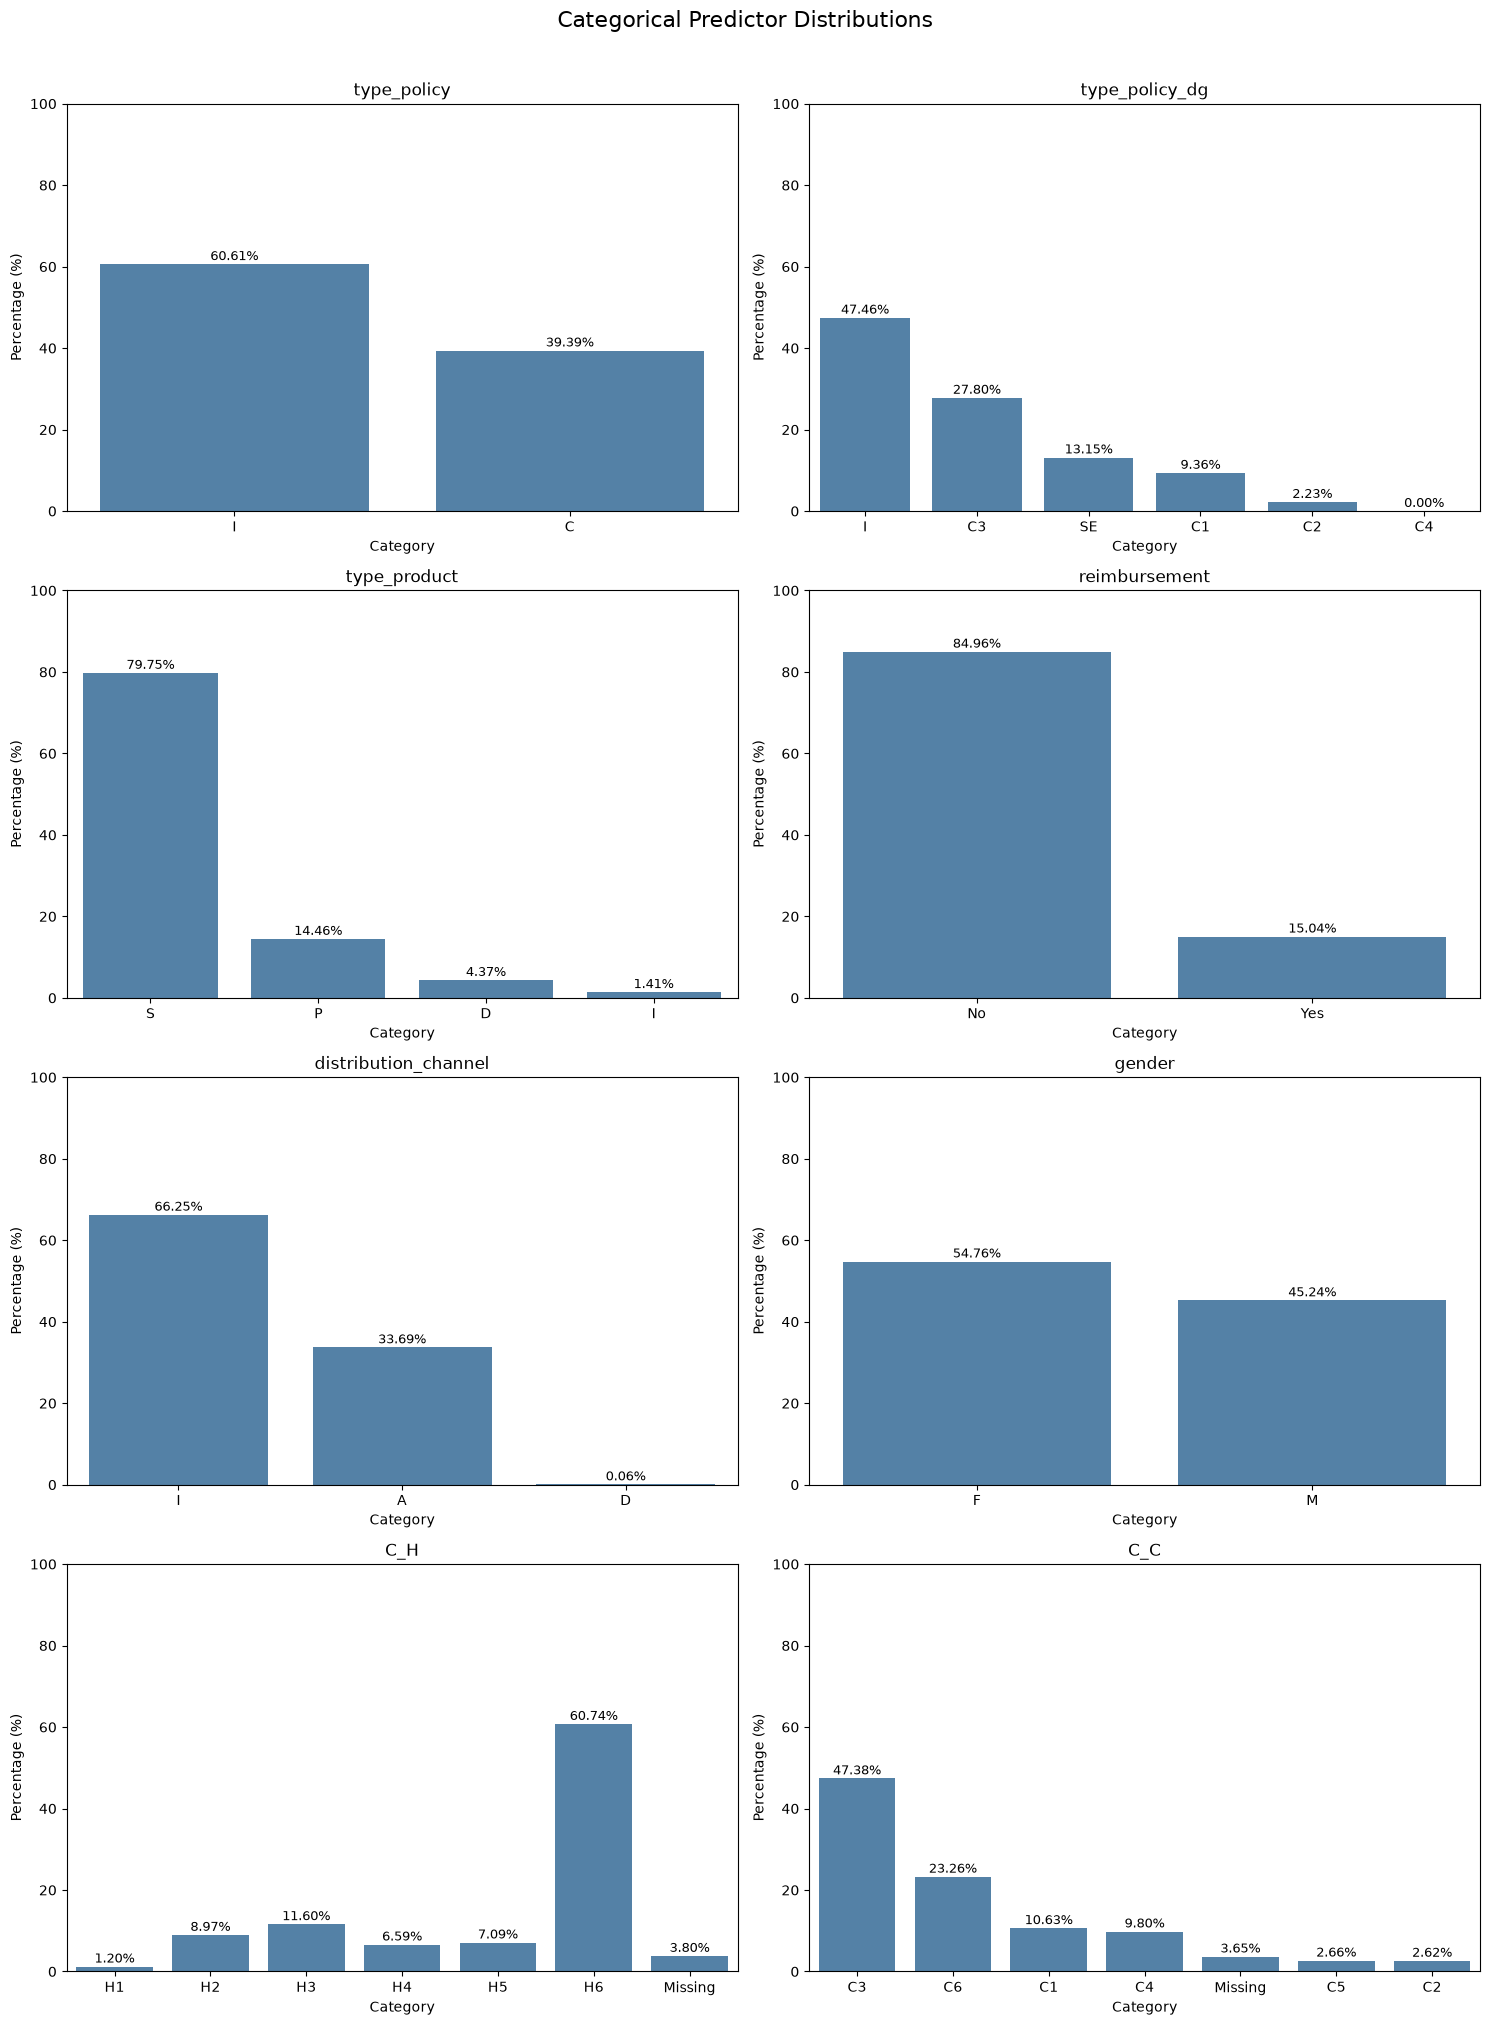

In [42]:
fig, axes = plt.subplots(4, 2, figsize=(15, 20))
axes = axes.flatten()

for i, col in enumerate(categorical_features):

    proportions = (
        df[col]
        .fillna("Missing")
        .value_counts(normalize=True)
        .mul(100)
    )

    # Preserve the meaningful order of habitat categories
    if col == "C_H":
        order = ["H1", "H2", "H3", "H4", "H5", "H6", "Missing"]
        proportions = proportions.reindex(order).dropna()

    sns.barplot(
        x=proportions.index,
        y=proportions.values,
        ax=axes[i],
        color="steelblue"
    )

    axes[i].set_title(col)
    axes[i].set_xlabel("Category")
    axes[i].set_ylabel("Percentage (%)")
    axes[i].set_ylim(0, 100)

    for j, value in enumerate(proportions.values):
        axes[i].text(
            j, value + 1,
            f"{value:.2f}%",
            ha="center",
            fontsize=9
        )

plt.suptitle(
    "Categorical Predictor Distributions",
    fontsize=16,
    y=1.01
)

plt.tight_layout()
plt.show()

In [43]:
expected_categories = {
    "type_policy": {"I", "C"},
    "type_policy_dg": {"S", "I", "C1", "C2", "C3", "C4"},
    "type_product": {"D", "P", "S", "I"},
    "reimbursement": {"Yes", "No"},
    "distribution_channel": {"A", "D", "I"},
    "gender": {"M", "F"},
    "C_H": {f"H{i}" for i in range(1, 7)},
    "C_C": {f"C{i}" for i in range(1, 7)}
}

audit_results = []

for col in categorical_features:
    values = df[col].astype("string")
    observed = set(values.dropna().unique())

    unexpected = observed - expected_categories[col]

    audit_results.append({
        "Feature": col,
        "Missing": values.isna().sum(),
        "Blank": values.fillna("").str.strip().eq("").sum()
                 - values.isna().sum(),
        "Unknown labels": values.fillna("").str.strip().str.lower()
                         .isin(["unknown", "unk", "n/a", "na", "null", "none", "?"])
                         .sum(),
        "Whitespace issues": (
            values.dropna() != values.dropna().str.strip()
        ).sum(),
        "Unexpected categories": sorted(unexpected),
        "Unexpected count": values.isin(unexpected).sum()
    })

audit_df = pd.DataFrame(audit_results)

display(audit_df)

,Feature,Missing,Blank,Unknown labels,Whitespace issues,Unexpected categories,Unexpected count
0,type_policy,0,0,0,0,[],0
1,type_policy_dg,0,0,0,0,[SE],21385
2,type_product,0,0,0,0,[],0
3,reimbursement,0,0,0,0,[],0
4,distribution_channel,0,0,0,0,[],0
5,gender,0,0,0,0,[],0
6,C_H,6188,0,0,0,[],0
7,C_C,5937,0,0,0,[],0


In [44]:
df["type_policy_dg"] = df["type_policy_dg"].replace({"SE": "S"})

In [45]:
df["type_policy_dg"].value_counts()

type_policy_dg
I     77180
C3    45205
S     21385
C1    15230
C2     3625
C4        4
Name: count, dtype: int64

In [46]:
df_2017 = df[df["period"] == 2017]

rare_results = []

for col in categorical_features:
    counts = df_2017[col].value_counts(dropna=True)

    for category, count in counts.items():
        percentage = count / len(df_2017) * 100

        rare_results.append({
            "Feature": col,
            "Category": category,
            "Count": count,
            "Percentage (%)": round(percentage, 4),
            "Below 0.1%": percentage < 0.1,
            "Below 0.5%": percentage < 0.5,
            "Below 1%": percentage < 1
        })

rare_df = pd.DataFrame(rare_results)

display(
    rare_df[rare_df["Below 1%"]]
    .sort_values("Percentage (%)")
)

,Feature,Category,Count,Percentage (%),Below 0.1%,Below 0.5%,Below 1%
15,distribution_channel,D,4,0.0071,True,True,True


In [47]:
pd.crosstab(
    df["period"],
    df["type_policy_dg"]
)[["C4"]]

type_policy_dg,C4
period,
2017,0
2018,4
2019,0


In [48]:
pd.crosstab(
    df["period"],
    df["distribution_channel"]
)[["D"]]

distribution_channel,D
period,
2017,4
2018,2
2019,90


In [49]:
imbalance_results = []

for col in categorical_features:
    counts = df_2017[col].value_counts(dropna=False)
    proportions = counts / len(df_2017) * 100

    imbalance_results.append({
        "Feature": col,
        "Categories": len(counts),
        "Dominant Category": str(counts.index[0]),
        "Dominant Count": counts.iloc[0],
        "Dominant (%)": round(proportions.iloc[0], 2),
        "Above 95%": proportions.iloc[0] >= 95,
        "Above 99%": proportions.iloc[0] >= 99
    })

imbalance_df = pd.DataFrame(imbalance_results)

display(
    imbalance_df.sort_values(
        "Dominant (%)", ascending=False
    )
)

,Feature,Categories,Dominant Category,Dominant Count,Dominant (%),Above 95%,Above 99%
3,reimbursement,2,No,49399,88.21,False,False
2,type_product,4,S,46391,82.84,False,False
4,distribution_channel,3,I,38038,67.93,False,False
6,C_H,7,H6,34373,61.38,False,False
0,type_policy,2,I,33320,59.50,False,False
5,gender,2,F,30505,54.47,False,False
7,C_C,7,C3,26970,48.16,False,False
1,type_policy_dg,5,I,25841,46.15,False,False


In [50]:
shift_results = []

for col in categorical_features:

    yearwise = pd.crosstab(
        df["period"],
        df[col].fillna("Missing"),
        normalize="index"
    ) * 100

    for category in yearwise.columns:

        shift_results.append({
            "Feature": col,
            "Category": category,
            "2017 (%)": round(yearwise.loc[2017, category], 2),
            "2018 (%)": round(yearwise.loc[2018, category], 2),
            "2019 (%)": round(yearwise.loc[2019, category], 2),
            "Max Change (pp)": round(
                yearwise[category].max() - yearwise[category].min(), 2
            )
        })

shift_df = pd.DataFrame(shift_results)

display(
    shift_df.sort_values(
        "Max Change (pp)", ascending=False
    ).head(15)
)

,Feature,Category,2017 (%),2018 (%),2019 (%),Max Change (pp)
10,type_product,P,10.90,15.27,17.42,6.52
13,reimbursement,Yes,11.79,15.69,17.80,6.02
12,reimbursement,No,88.21,84.31,82.20,6.02
11,type_product,S,82.84,79.13,77.12,5.73
16,distribution_channel,I,67.93,66.28,64.45,3.47
14,distribution_channel,A,32.07,33.72,35.38,3.31
6,type_policy_dg,I,46.15,46.87,49.44,3.29
4,type_policy_dg,C3,29.03,28.09,26.20,2.83
0,type_policy,C,40.50,39.75,37.86,2.64
1,type_policy,I,59.50,60.25,62.14,2.64


In [51]:
shift_results = []

for col in categorical_features:

    yearwise = pd.crosstab(
        df["period"],
        df[col].fillna("Missing"),
        normalize="index"
    ) * 100

    for category in yearwise.columns:

        shift_results.append({
            "Feature": col,
            "Category": category,
            "2017 (%)": round(yearwise.loc[2017, category], 2),
            "2018 (%)": round(yearwise.loc[2018, category], 2),
            "2019 (%)": round(yearwise.loc[2019, category], 2),
            "Max Change (pp)": round(
                yearwise[category].max() - yearwise[category].min(), 2
            )
        })

shift_df = pd.DataFrame(shift_results)

display(
    shift_df.sort_values(
        "Max Change (pp)", ascending=False
    ).head(15)
)

,Feature,Category,2017 (%),2018 (%),2019 (%),Max Change (pp)
10,type_product,P,10.90,15.27,17.42,6.52
13,reimbursement,Yes,11.79,15.69,17.80,6.02
12,reimbursement,No,88.21,84.31,82.20,6.02
11,type_product,S,82.84,79.13,77.12,5.73
16,distribution_channel,I,67.93,66.28,64.45,3.47
14,distribution_channel,A,32.07,33.72,35.38,3.31
6,type_policy_dg,I,46.15,46.87,49.44,3.29
4,type_policy_dg,C3,29.03,28.09,26.20,2.83
0,type_policy,C,40.50,39.75,37.86,2.64
1,type_policy,I,59.50,60.25,62.14,2.64


In [52]:
cross_tab = pd.crosstab(
    df["type_policy"],
    df["type_policy_dg"]
)

display(cross_tab)

type_policy_dg,C1,C2,C3,C4,I,S
type_policy,,,,,,
C,15230,3625,45205,4,0,0
I,0,0,0,0,77180,21385


In [53]:
cross_tab_pct = pd.crosstab(
    df["type_policy"],
    df["type_policy_dg"],
    normalize="index"
) * 100

display(cross_tab_pct.round(2))

type_policy_dg,C1,C2,C3,C4,I,S
type_policy,,,,,,
C,23.77,5.66,70.56,0.01,0.0,0.0
I,0.00,0.00,0.00,0.00,78.3,21.7


In [54]:
cross_tab = pd.crosstab(
    df["type_product"],
    df["type_policy_dg"]
)

display(cross_tab)

type_policy_dg,C1,C2,C3,C4,I,S
type_product,,,,,,
D,336,0,0,0,6772,0
I,233,0,0,0,2064,0
P,3366,0,0,0,14343,5814
S,11295,3625,45205,4,54001,15571


In [55]:
cross_tab = pd.crosstab(
    df["type_product"],
    df["type_policy_dg"]
)

display(cross_tab)

type_policy_dg,C1,C2,C3,C4,I,S
type_product,,,,,,
D,336,0,0,0,6772,0
I,233,0,0,0,2064,0
P,3366,0,0,0,14343,5814
S,11295,3625,45205,4,54001,15571


In [56]:
from scipy.stats import chi2_contingency
from itertools import combinations

association_results = []

for col1, col2 in combinations(categorical_features, 2):

    table = pd.crosstab(
        df[col1].astype("string").fillna("Missing"),
        df[col2].astype("string").fillna("Missing")
    )

    chi2 = chi2_contingency(table, correction=False)[0]
    n = table.to_numpy().sum()

    v = np.sqrt(
        (chi2 / n) / min(table.shape[0] - 1, table.shape[1] - 1)
    )

    association_results.append({
        "Feature 1": col1,
        "Feature 2": col2,
        "Cramer's V": round(v, 4)
    })

association_df = pd.DataFrame(association_results)

display(
    association_df.sort_values(
        "Cramer's V", ascending=False
    )
)

,Feature 1,Feature 2,Cramer's V
0,type_policy,type_policy_dg,1.0000
13,type_product,reimbursement,0.9866
6,type_policy,C_C,0.5311
27,C_H,C_C,0.4259
12,type_policy_dg,C_C,0.3200
1,type_policy,type_product,0.2853
8,type_policy_dg,reimbursement,0.2848
5,type_policy,C_H,0.2573
9,type_policy_dg,distribution_channel,0.2212
3,type_policy,distribution_channel,0.2206


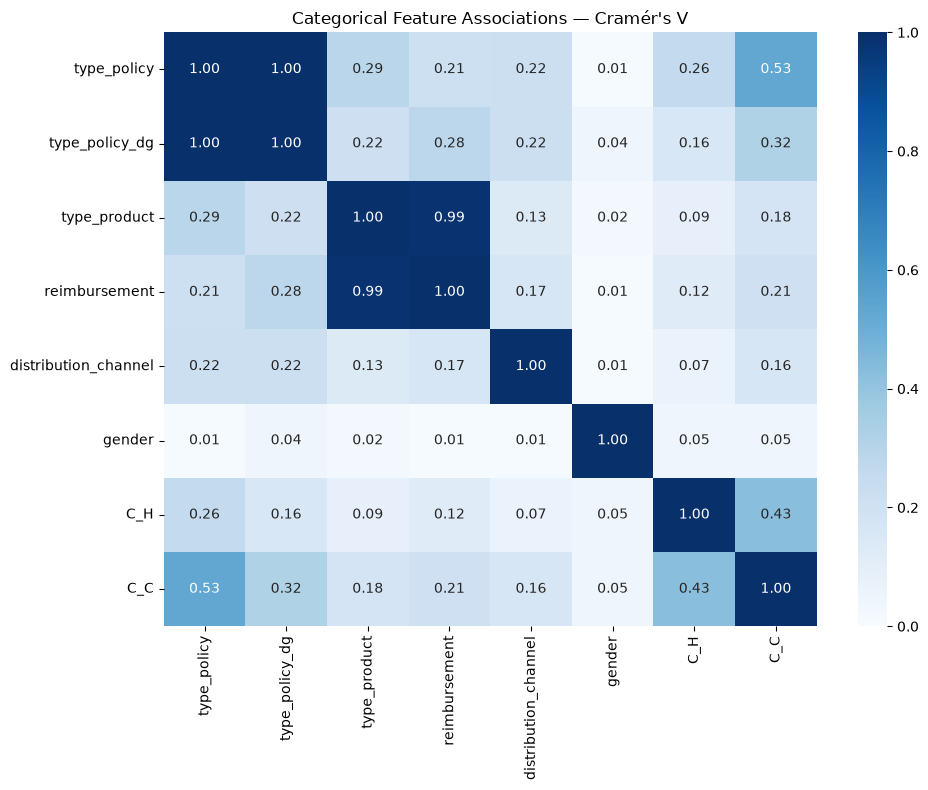

In [57]:
association_matrix = pd.DataFrame(
    np.eye(len(categorical_features)),
    index=categorical_features,
    columns=categorical_features
)

for _, row in association_df.iterrows():
    a, b, v = row["Feature 1"], row["Feature 2"], row["Cramer's V"]

    association_matrix.loc[a, b] = v
    association_matrix.loc[b, a] = v

plt.figure(figsize=(10, 8))

sns.heatmap(
    association_matrix,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=0,
    vmax=1
)

plt.title("Categorical Feature Associations — Cramér's V")
plt.tight_layout()
plt.show()

In [58]:
cross_tab = pd.crosstab(
    df["type_product"],
    df["reimbursement"]
)

display(cross_tab)

cross_tab_pct = pd.crosstab(
    df["type_product"],
    df["reimbursement"],
    normalize="index"
).mul(100).round(2)

display(cross_tab_pct)

reimbursement,No,Yes
type_product,,
D,7108,0
I,1365,932
P,0,23523
S,129701,0


reimbursement,No,Yes
type_product,,
D,100.00,0.00
I,59.43,40.57
P,0.00,100.00
S,100.00,0.00


## Target Variable Analysis 

In [59]:
target = df["premium"]

print("Total observations:", len(target))
print("Missing premiums:", target.isna().sum())
print("Zero premiums:", (target == 0).sum())
print("Negative premiums:", (target < 0).sum())
print("Unique premiums:", target.nunique())

display(
    target.describe(
        percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
    )
)

Total observations: 162629
Missing premiums: 0
Zero premiums: 0
Negative premiums: 0
Unique premiums: 34006


count    162629.000000
mean        931.292181
std         569.156203
min          33.330000
1%           95.253100
5%          292.128000
25%         633.977000
50%         853.740000
75%        1083.240000
95%        1854.360000
99%        2928.134400
max       15339.780000
Name: premium, dtype: float64

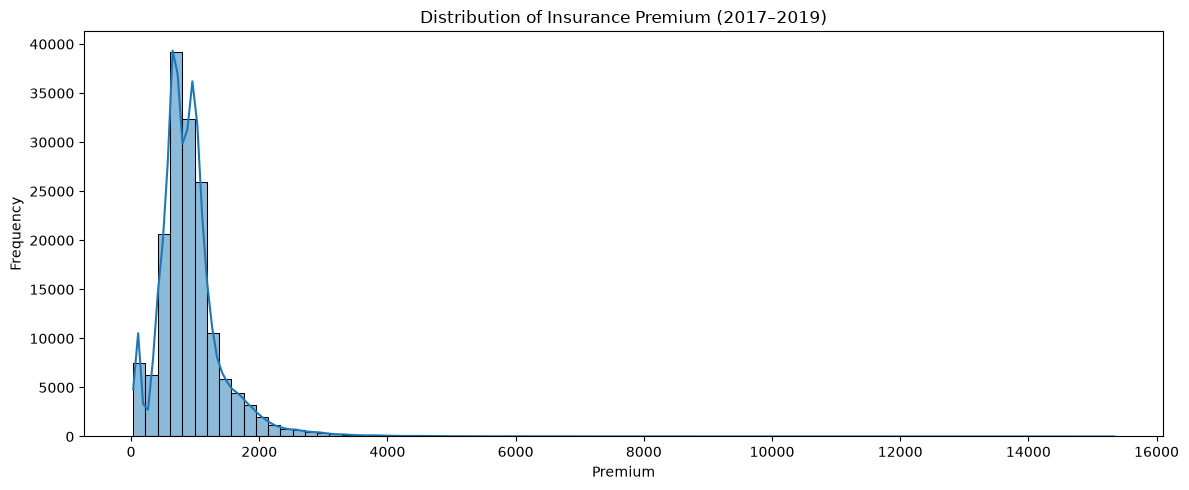

In [60]:
plt.figure(figsize=(12, 5))

sns.histplot(
    df["premium"],
    bins=80,
    kde=True
)

plt.title("Distribution of Insurance Premium (2017–2019)")
plt.xlabel("Premium")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

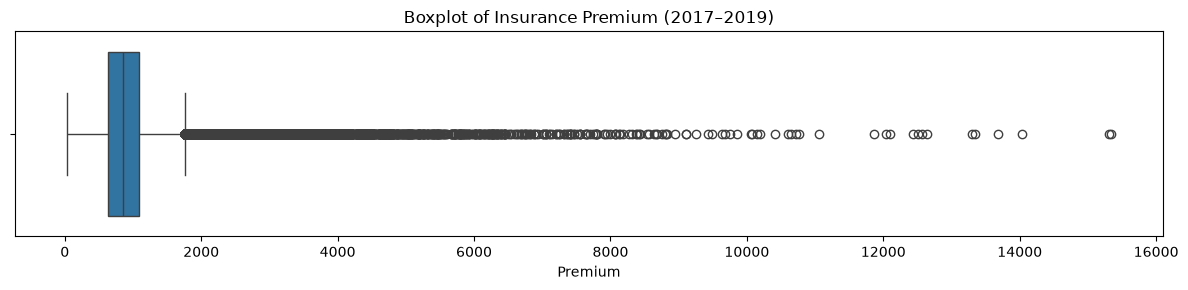

In [61]:
plt.figure(figsize=(12, 3))

sns.boxplot(x=df["premium"])

plt.title("Boxplot of Insurance Premium (2017–2019)")
plt.xlabel("Premium")
plt.tight_layout()
plt.show()

In [62]:
Q1 = df["premium"].quantile(0.25)
Q3 = df["premium"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = (
    (df["premium"] < lower_bound) |
    (df["premium"] > upper_bound)
)

print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Observations beyond IQR bounds:", outliers.sum())
print("Percentage:", round(outliers.mean() * 100, 2))

IQR: 449.26300000000003
Lower bound: -39.91750000000013
Upper bound: 1757.1345000000001
Observations beyond IQR bounds: 9882
Percentage: 6.08


Skewness: 4.165853017531113
Excess kurtosis: 45.489779098345906


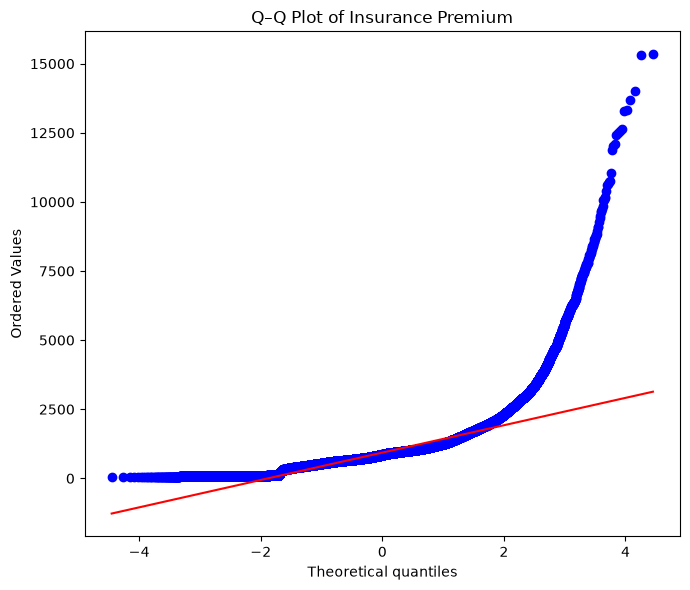

In [63]:
from scipy import stats

print("Skewness:", df["premium"].skew())
print("Excess kurtosis:", df["premium"].kurt())

plt.figure(figsize=(7, 6))

stats.probplot(
    df["premium"],
    dist="norm",
    plot=plt
)

plt.title("Q–Q Plot of Insurance Premium")
plt.tight_layout()
plt.show()

In [64]:
threshold = df["premium"].quantile(0.99)

extreme = df[df["premium"] > threshold]

print("99th percentile:", threshold)
print("Extreme observations:", len(extreme))
print("Percentage:", round(len(extreme) / len(df) * 100, 2))

print("\nExtreme premium statistics:")
display(extreme["premium"].describe())

print("\nTop 10 highest premiums:")
display(
    df.nlargest(10, "premium")[
        [
            "premium",
            "type_policy_dg",
            "type_product",
            "reimbursement",
            "C_H",
            "C_C"
        ]
    ]
)

99th percentile: 2928.1344000000013
Extreme observations: 1627
Percentage: 1.0

Extreme premium statistics:


count     1627.000000
mean      4167.987922
std       1586.858583
min       2928.420000
25%       3165.904800
50%       3580.200000
75%       4538.435000
max      15339.780000
Name: premium, dtype: float64


Top 10 highest premiums:


,premium,type_policy_dg,type_product,reimbursement,C_H,C_C
2957,15339.7800,I,S,No,H6,C4
112098,15307.5888,I,S,No,H6,C4
1078,14027.8900,I,P,Yes,H6,C1
58721,13679.4400,I,S,No,H6,C4
126564,13341.0496,I,S,No,H3,C3
1217,13303.7200,I,P,Yes,H6,C6
74717,12647.2200,I,S,No,H3,C3
110496,12574.5808,I,P,Yes,H6,C1
131205,12506.8906,C1,S,No,H1,C5
20894,12429.7200,I,S,No,H3,C3


Original skewness: 4.165853017531113
Log skewness: -1.2976618003673286
Original kurtosis: 45.489779098345906
Log kurtosis: 3.80107683254072


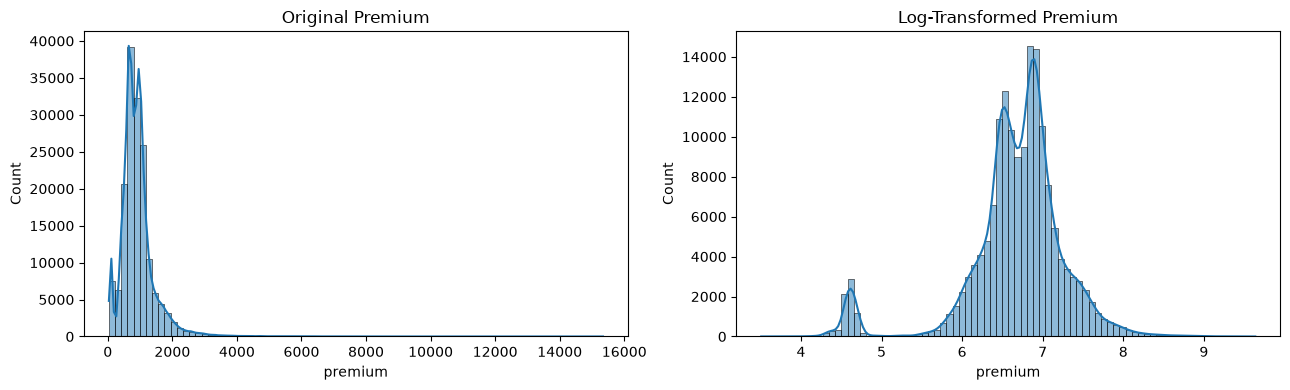

In [65]:
log_premium = np.log(df["premium"])

print("Original skewness:", df["premium"].skew())
print("Log skewness:", log_premium.skew())

print("Original kurtosis:", df["premium"].kurt())
print("Log kurtosis:", log_premium.kurt())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(df["premium"], bins=80, kde=True, ax=axes[0])
axes[0].set_title("Original Premium")

sns.histplot(log_premium, bins=80, kde=True, ax=axes[1])
axes[1].set_title("Log-Transformed Premium")

plt.tight_layout()
plt.show()

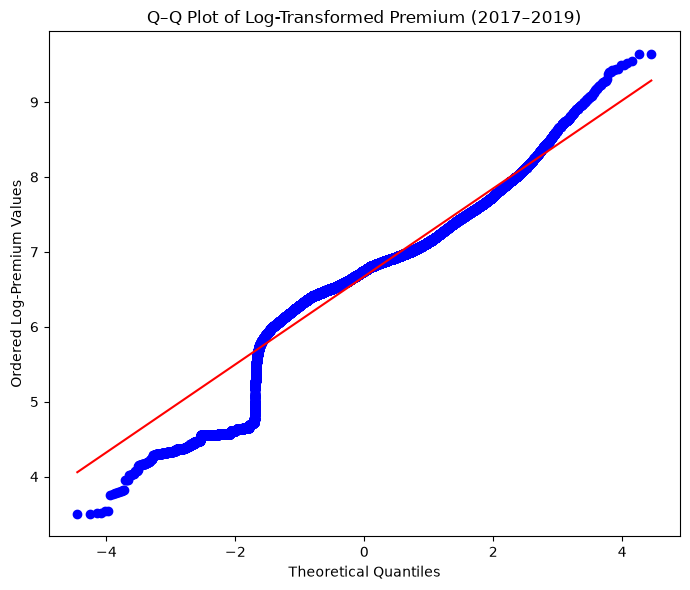

In [66]:
from scipy import stats

log_premium = np.log(df["premium"])

plt.figure(figsize=(7, 6))

stats.probplot(
    log_premium,
    dist="norm",
    plot=plt
)

plt.title("Q–Q Plot of Log-Transformed Premium (2017–2019)")
plt.xlabel("Theoretical Quantiles")
plt.ylabel("Ordered Log-Premium Values")
plt.tight_layout()
plt.show()

In [67]:
yearly_stats = df.groupby("period")["premium"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

display(yearly_stats.round(2))

,count,mean,median,std,min,max
period,,,,,,
2017,55999,898.09,836.28,555.34,33.33,15339.78
2018,53555,932.65,857.82,564.59,34.68,13679.44
2019,53075,964.95,874.62,585.89,43.68,15307.59


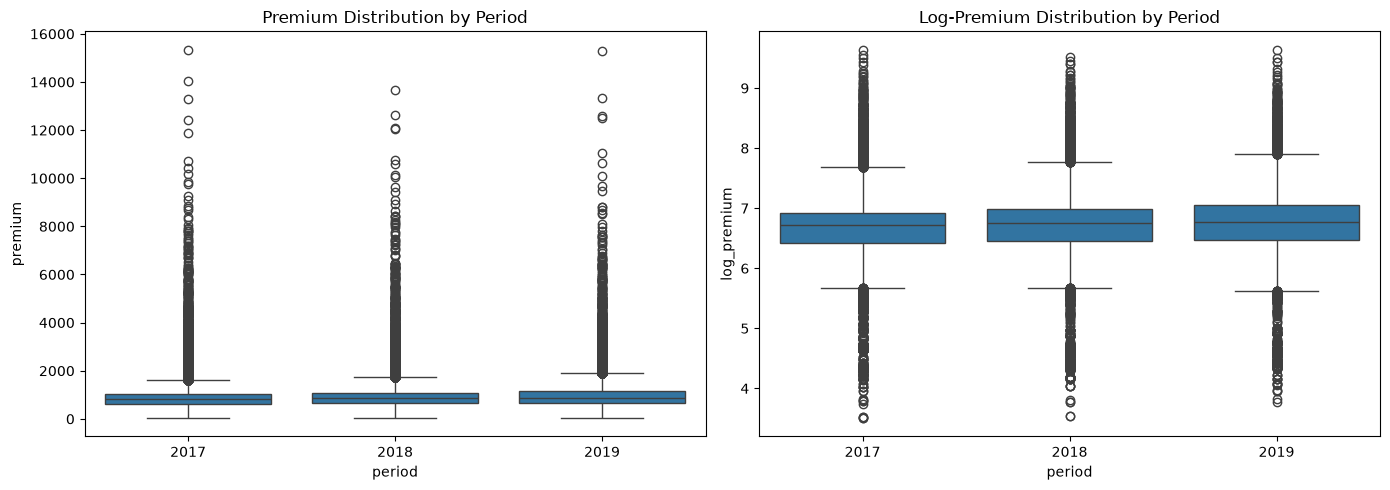

In [68]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df, x="period", y="premium", ax=axes[0])
axes[0].set_title("Premium Distribution by Period")

sns.boxplot(
    data=df.assign(log_premium=np.log(df["premium"])),
    x="period",
    y="log_premium",
    ax=axes[1]
)
axes[1].set_title("Log-Premium Distribution by Period")

plt.tight_layout()
plt.show()

In [69]:
yearly_shape = df.groupby("period")["premium"].agg(
    skewness="skew",
    kurtosis=pd.Series.kurt
)

yearly_shape["log_skewness"] = df.groupby("period")["premium"].apply(
    lambda x: np.log(x).skew()
)

yearly_shape["log_kurtosis"] = df.groupby("period")["premium"].apply(
    lambda x: np.log(x).kurt()
)

display(yearly_shape.round(4))

,skewness,kurtosis,log_skewness,log_kurtosis
period,,,,
2017,4.6815,55.5970,-1.2536,3.7803
2018,4.1461,43.5555,-1.3570,4.0496
2019,3.7347,38.9382,-1.3026,3.6479


## Predictor–Target Relationship Analysis

In [70]:
excluded = {
    "premium",
    "log_premium",
    "previous_premium",
    "period",
    "ID",
    "ID_policy",
    "ID_insured"
}

features = [
    col for col in numerical_features
    if col not in excluded
]

log_target = np.log(df["premium"])

correlation_results = pd.DataFrame({
    "Feature": features,
    "Pearson": [
        df[col].corr(log_target, method="pearson")
        for col in features
    ],
    "Spearman": [
        df[col].corr(log_target, method="spearman")
        for col in features
    ]
})

correlation_results["Max Absolute Correlation"] = (
    correlation_results[["Pearson", "Spearman"]]
    .abs()
    .max(axis=1)
)

display(
    correlation_results
    .sort_values("Max Absolute Correlation", ascending=False)
    .round(4)
)

,Feature,Pearson,Spearman,Max Absolute Correlation
3,age,0.3747,0.5438,0.5438
4,cost_claims_year,0.2009,0.3541,0.3541
5,n_medical_services,0.2818,0.3484,0.3484
1,seniority_insured,0.1949,0.3378,0.3378
2,seniority_policy,0.1681,0.3065,0.3065
8,n_insured_prov,-0.1852,-0.0901,0.1852
14,C_IE_S,-0.0723,-0.1481,0.1481
17,C_GE_S,-0.0736,-0.1424,0.1424
15,C_IE_T,0.0554,0.1282,0.1282
18,C_GE_T,0.0431,0.1278,0.1278


C:\Users\rajab\Desktop\ML-Health-Insurance\.venv\Lib\site-packages\statsmodels\nonparametric\smoothers_lowess.py:237: RuntimeWarning: invalid value encountered in divide
  res, _ = _lowess(


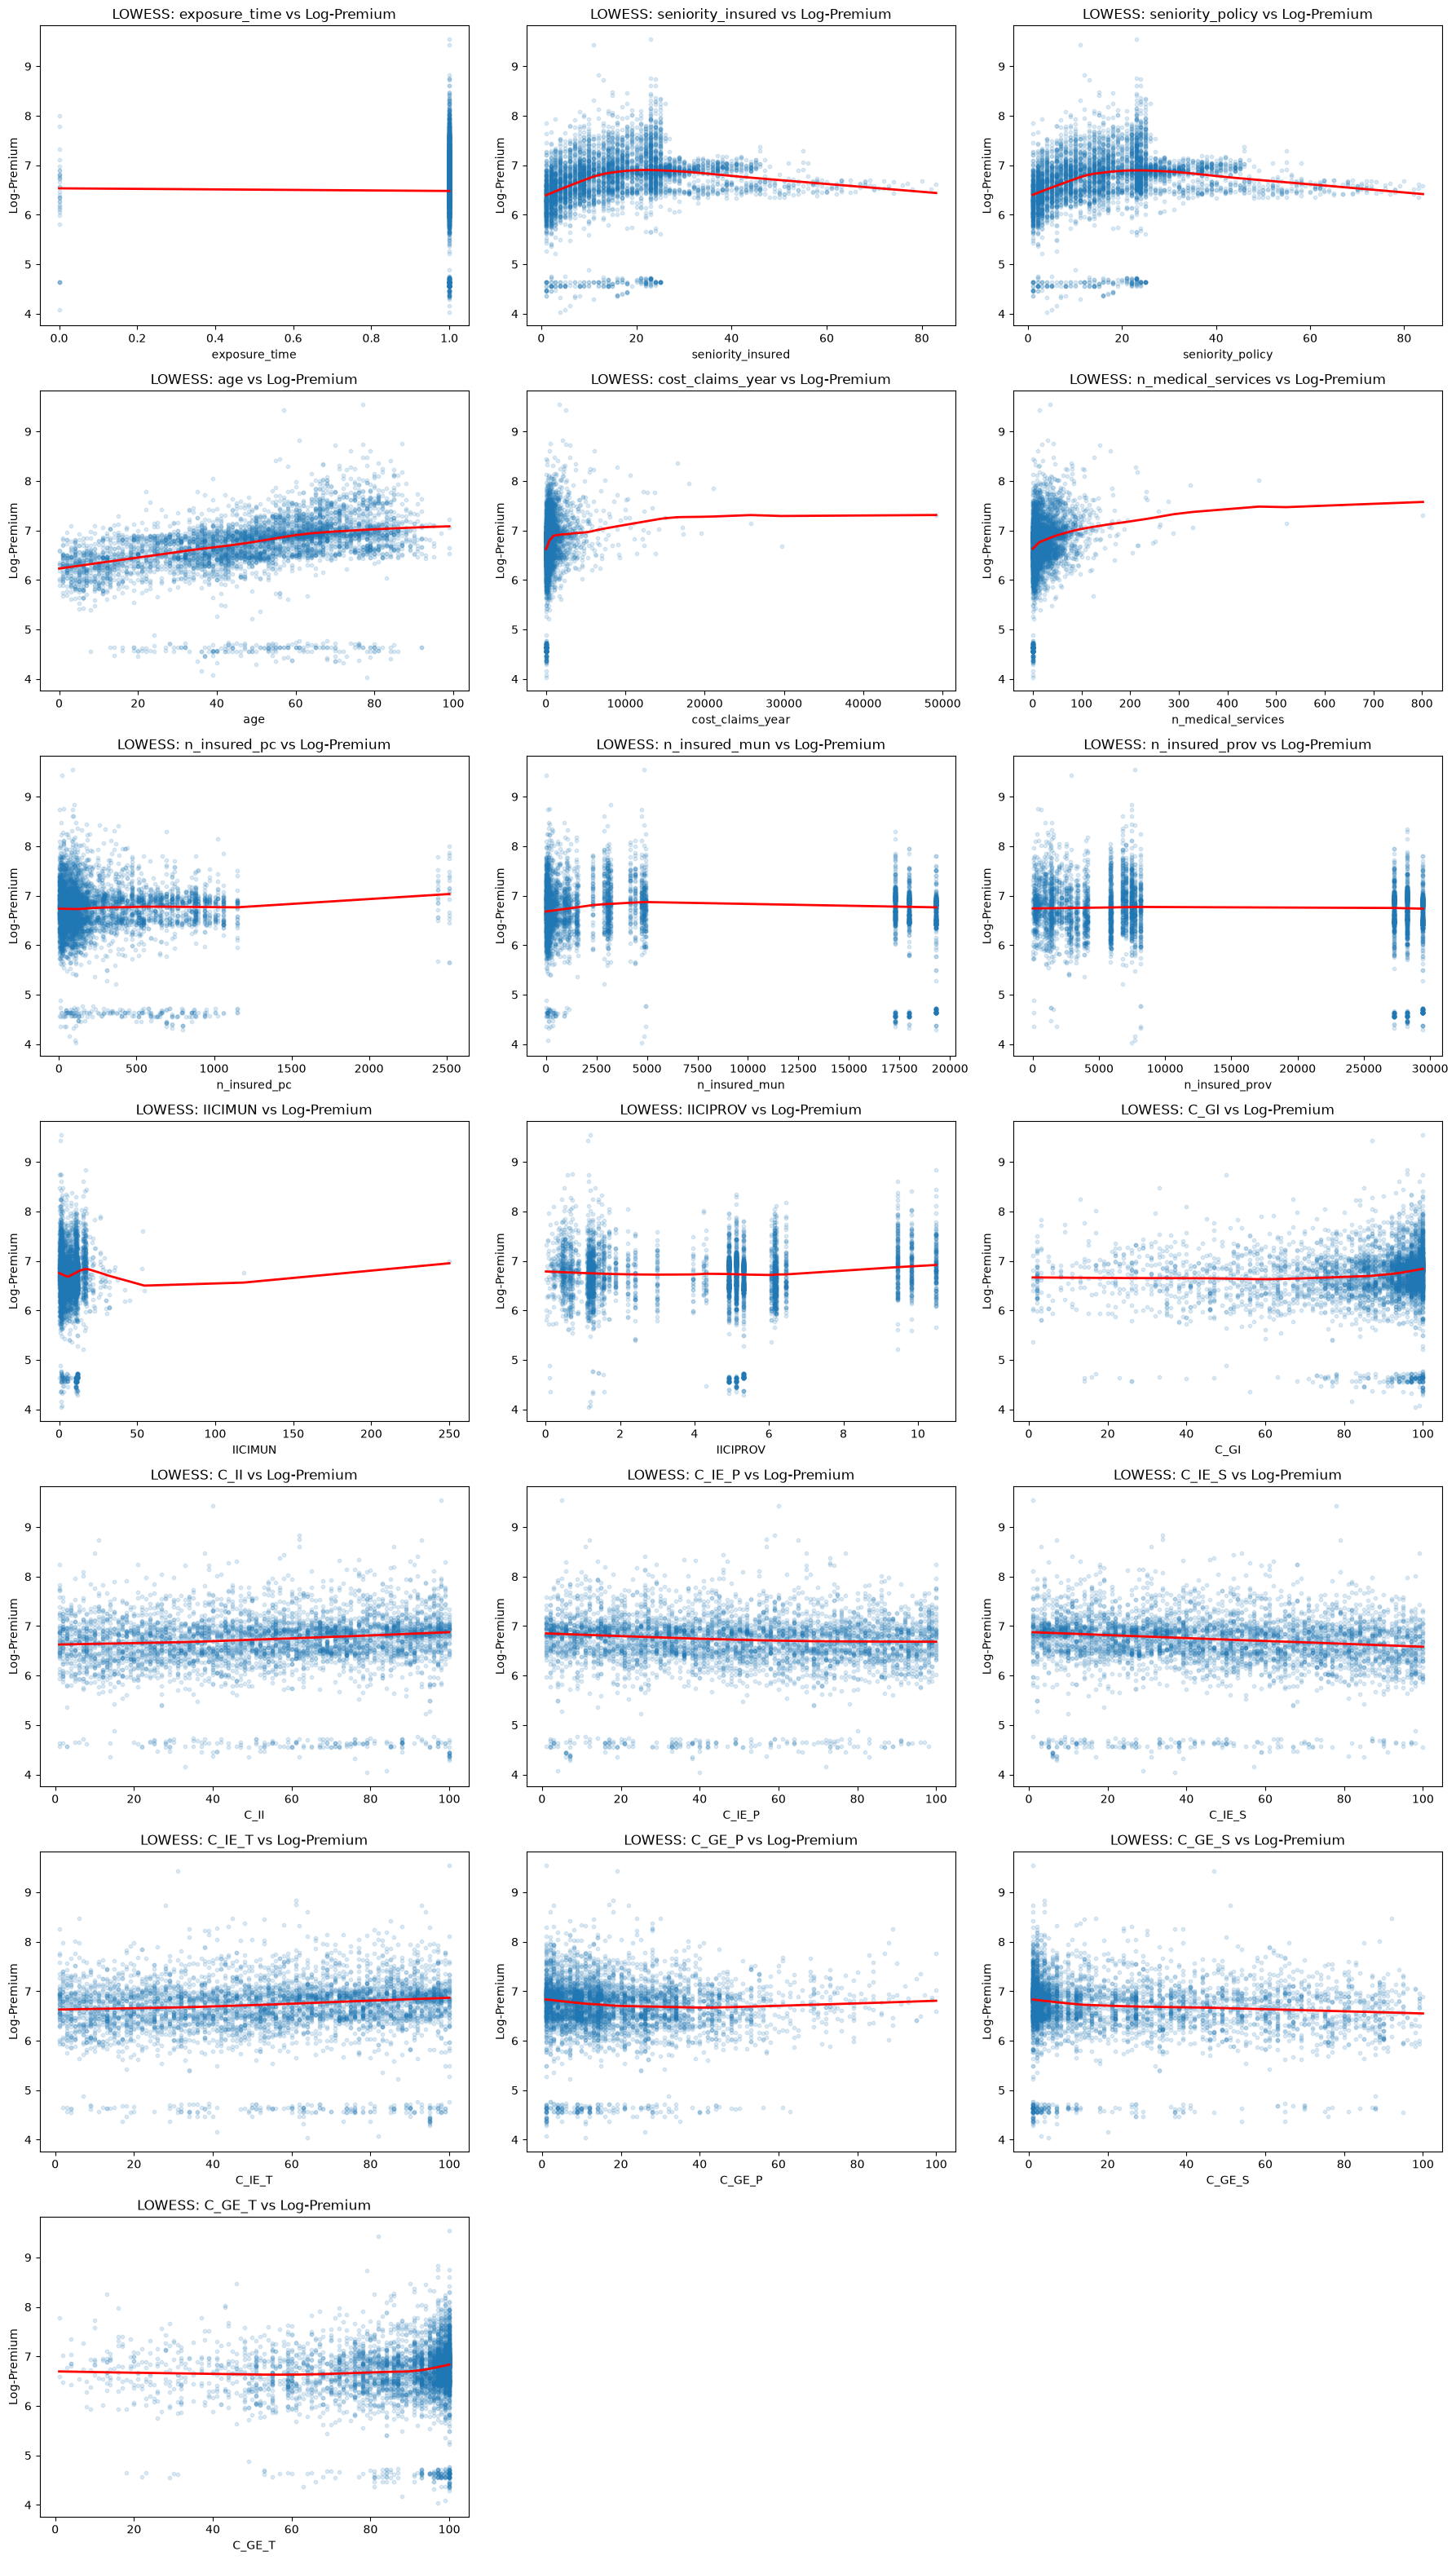

In [71]:
import math
excluded = {
    "premium", "log_premium", "previous_premium",
    "period", "ID", "ID_policy", "ID_insured"
}

features = [
    col for col in numerical_features
    if col not in excluded
]

# Sample for visualization and LOWESS computation
plot_df = df.sample(
    n=min(5000, len(df)),
    random_state=42
).copy()

plot_df["log_premium"] = np.log(plot_df["premium"])

ncols = 3
nrows = math.ceil(len(features) / ncols)

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(18, nrows * 4.5)
)

axes = np.array(axes).flatten()

for i, col in enumerate(features):

    sns.regplot(
        data=plot_df,
        x=col,
        y="log_premium",
        lowess=True,
        scatter_kws={
            "alpha": 0.15,
            "s": 10
        },
        line_kws={
            "color": "red",
            "linewidth": 2
        },
        ax=axes[i]
    )

    axes[i].set_title(f"LOWESS: {col} vs Log-Premium")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Log-Premium")

for j in range(len(features), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

In [72]:
from sklearn.feature_selection import mutual_info_regression

# Exclude target, identifiers and previous premium
excluded = {
    "premium", "log_premium", "previous_premium",
    "period", "ID", "ID_policy", "ID_insured"
}

features = [
    col for col in numerical_features
    if col not in excluded
]

# Prepare numerical predictors and log target
mi_df = df[features].copy()
mi_df["log_premium"] = np.log(df["premium"])

# Use complete observations for this analysis
mi_df = mi_df.dropna()

print("Complete observations:", len(mi_df))

# Reproducible sample
mi_sample = mi_df.sample(
    n=min(20000, len(mi_df)),
    random_state=42
)

X = mi_sample[features]
y = mi_sample["log_premium"]

# Mark known binary feature as discrete
discrete_mask = [
    col == "exposure_time"
    for col in features
]

# Calculate Mutual Information
mi_scores = mutual_info_regression(
    X,
    y,
    discrete_features=discrete_mask,
    n_neighbors=5,
    random_state=42
)

mi_results = pd.DataFrame({
    "Feature": features,
    "Mutual Information": mi_scores
}).sort_values(
    "Mutual Information",
    ascending=False
)

display(mi_results.round(4))

Complete observations: 154442


,Feature,Mutual Information
8,n_insured_prov,0.4879
10,IICIPROV,0.4852
7,n_insured_mun,0.3950
9,IICIMUN,0.3818
2,seniority_policy,0.3660
1,seniority_insured,0.3456
3,age,0.3454
6,n_insured_pc,0.1376
5,n_medical_services,0.1279
4,cost_claims_year,0.1274


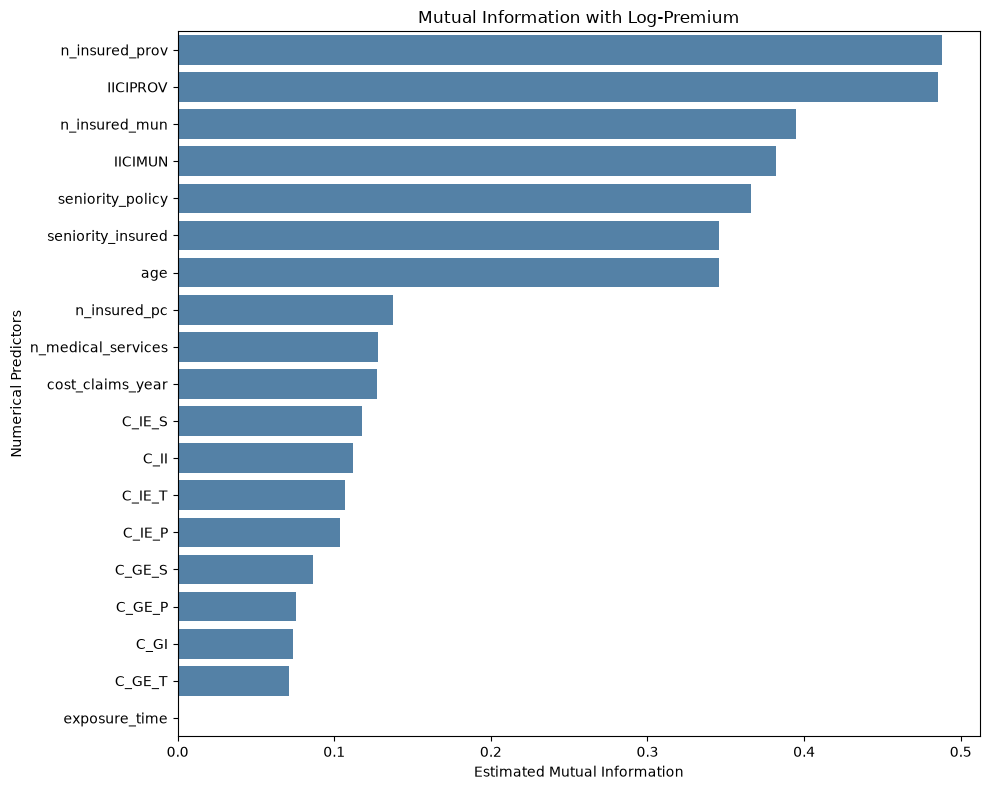

In [73]:
plt.figure(figsize=(10, 8))

sns.barplot(
    data=mi_results,
    x="Mutual Information",
    y="Feature",
    color="steelblue"
)

plt.title("Mutual Information with Log-Premium")
plt.xlabel("Estimated Mutual Information")
plt.ylabel("Numerical Predictors")

plt.tight_layout()
plt.show()

In [74]:
analysis_df = df.copy()

analysis_df["log_premium"] = np.log(
    analysis_df["premium"]
)

categorical_results = {}

for col in categorical_features:

    summary = (
        analysis_df
        .groupby(col, dropna=False)
        .agg(
            Count=("premium", "size"),
            Mean_Premium=("premium", "mean"),
            Median_Premium=("premium", "median"),
            Mean_Log_Premium=("log_premium", "mean"),
            Median_Log_Premium=("log_premium", "median"),
            Std_Log_Premium=("log_premium", "std")
        )
        .reset_index()
    )

    summary["Percentage"] = (
        summary["Count"] / len(analysis_df) * 100
    )

    summary = summary[
        [
            col,
            "Count",
            "Percentage",
            "Mean_Premium",
            "Median_Premium",
            "Mean_Log_Premium",
            "Median_Log_Premium",
            "Std_Log_Premium"
        ]
    ]

    categorical_results[col] = summary

    print(f"\n{'=' * 60}")
    print(f"Feature: {col}")
    print(f"{'=' * 60}")

    display(summary.round(4))


Feature: type_policy


,type_policy,Count,Percentage,Mean_Premium,Median_Premium,Mean_Log_Premium,Median_Log_Premium,Std_Log_Premium
0,C,64064,39.3927,832.1556,832.1372,6.6677,6.7240,0.3605
1,I,98565,60.6073,995.7277,864.9600,6.6765,6.7627,0.7495



Feature: type_policy_dg


,type_policy_dg,Count,Percentage,Mean_Premium,Median_Premium,Mean_Log_Premium,Median_Log_Premium,Std_Log_Premium
0,C1,15230,9.3649,673.9207,610.0400,6.3876,6.4135,0.5180
1,C2,3625,2.2290,837.8636,849.6600,6.6880,6.7448,0.2983
2,C3,45205,27.7964,885.0351,919.1000,6.7604,6.8234,0.2271
3,C4,4,0.0025,535.5300,560.5500,6.2792,6.3289,0.1061
4,I,77180,47.4577,1066.4509,932.2800,6.7172,6.8376,0.8175
5,S,21385,13.1496,740.4824,678.2592,6.5298,6.5195,0.3870



Feature: type_product


,type_product,Count,Percentage,Mean_Premium,Median_Premium,Mean_Log_Premium,Median_Log_Premium,Std_Log_Premium
0,D,7108,4.3707,99.3433,100.9800,4.5941,4.6149,0.0966
1,I,2297,1.4124,1079.9774,904.5964,6.5805,6.8075,1.0210
2,P,23523,14.4642,1016.3845,763.5600,6.7256,6.6380,0.5947
3,S,129701,79.7527,958.8196,893.5200,6.7791,6.7952,0.3991


... (6 outputs left out)


Feature: C_H


,C_H,Count,Percentage,Mean_Premium,Median_Premium,Mean_Log_Premium,Median_Log_Premium,Std_Log_Premium
0,H1,1952,1.2003,950.2058,835.3250,6.7296,6.7278,0.4964
1,H2,14581,8.9658,899.4062,809.8800,6.6695,6.6969,0.5374
2,H3,18869,11.6025,917.2966,806.8200,6.6783,6.6931,0.5550
3,H4,10722,6.5929,876.6302,789.4800,6.6112,6.6714,0.6182
4,H5,11531,7.0904,882.6984,799.0514,6.6311,6.6834,0.5879
5,H6,98786,60.7432,931.1859,871.0800,6.6634,6.7697,0.6583
6,NaN,6188,3.8050,1230.0991,1054.1870,6.9860,6.9605,0.5107



Feature: C_C


,C_C,Count,Percentage,Mean_Premium,Median_Premium,Mean_Log_Premium,Median_Log_Premium,Std_Log_Premium
0,C1,17283,10.6273,989.8880,876.1800,6.7554,6.7756,0.5352
1,C2,4261,2.6201,1126.6986,965.9400,6.8969,6.8731,0.5088
2,C3,77057,47.3821,827.5048,817.0900,6.5436,6.7057,0.6945
3,C4,15937,9.7996,925.3305,797.6273,6.7087,6.6816,0.4813
4,C5,4331,2.6631,1010.6024,835.8760,6.7490,6.7285,0.5705
5,C6,37823,23.2572,1039.7987,874.1400,6.8007,6.7732,0.5384
6,NaN,5937,3.6506,1234.4220,1052.9654,6.9890,6.9594,0.5089


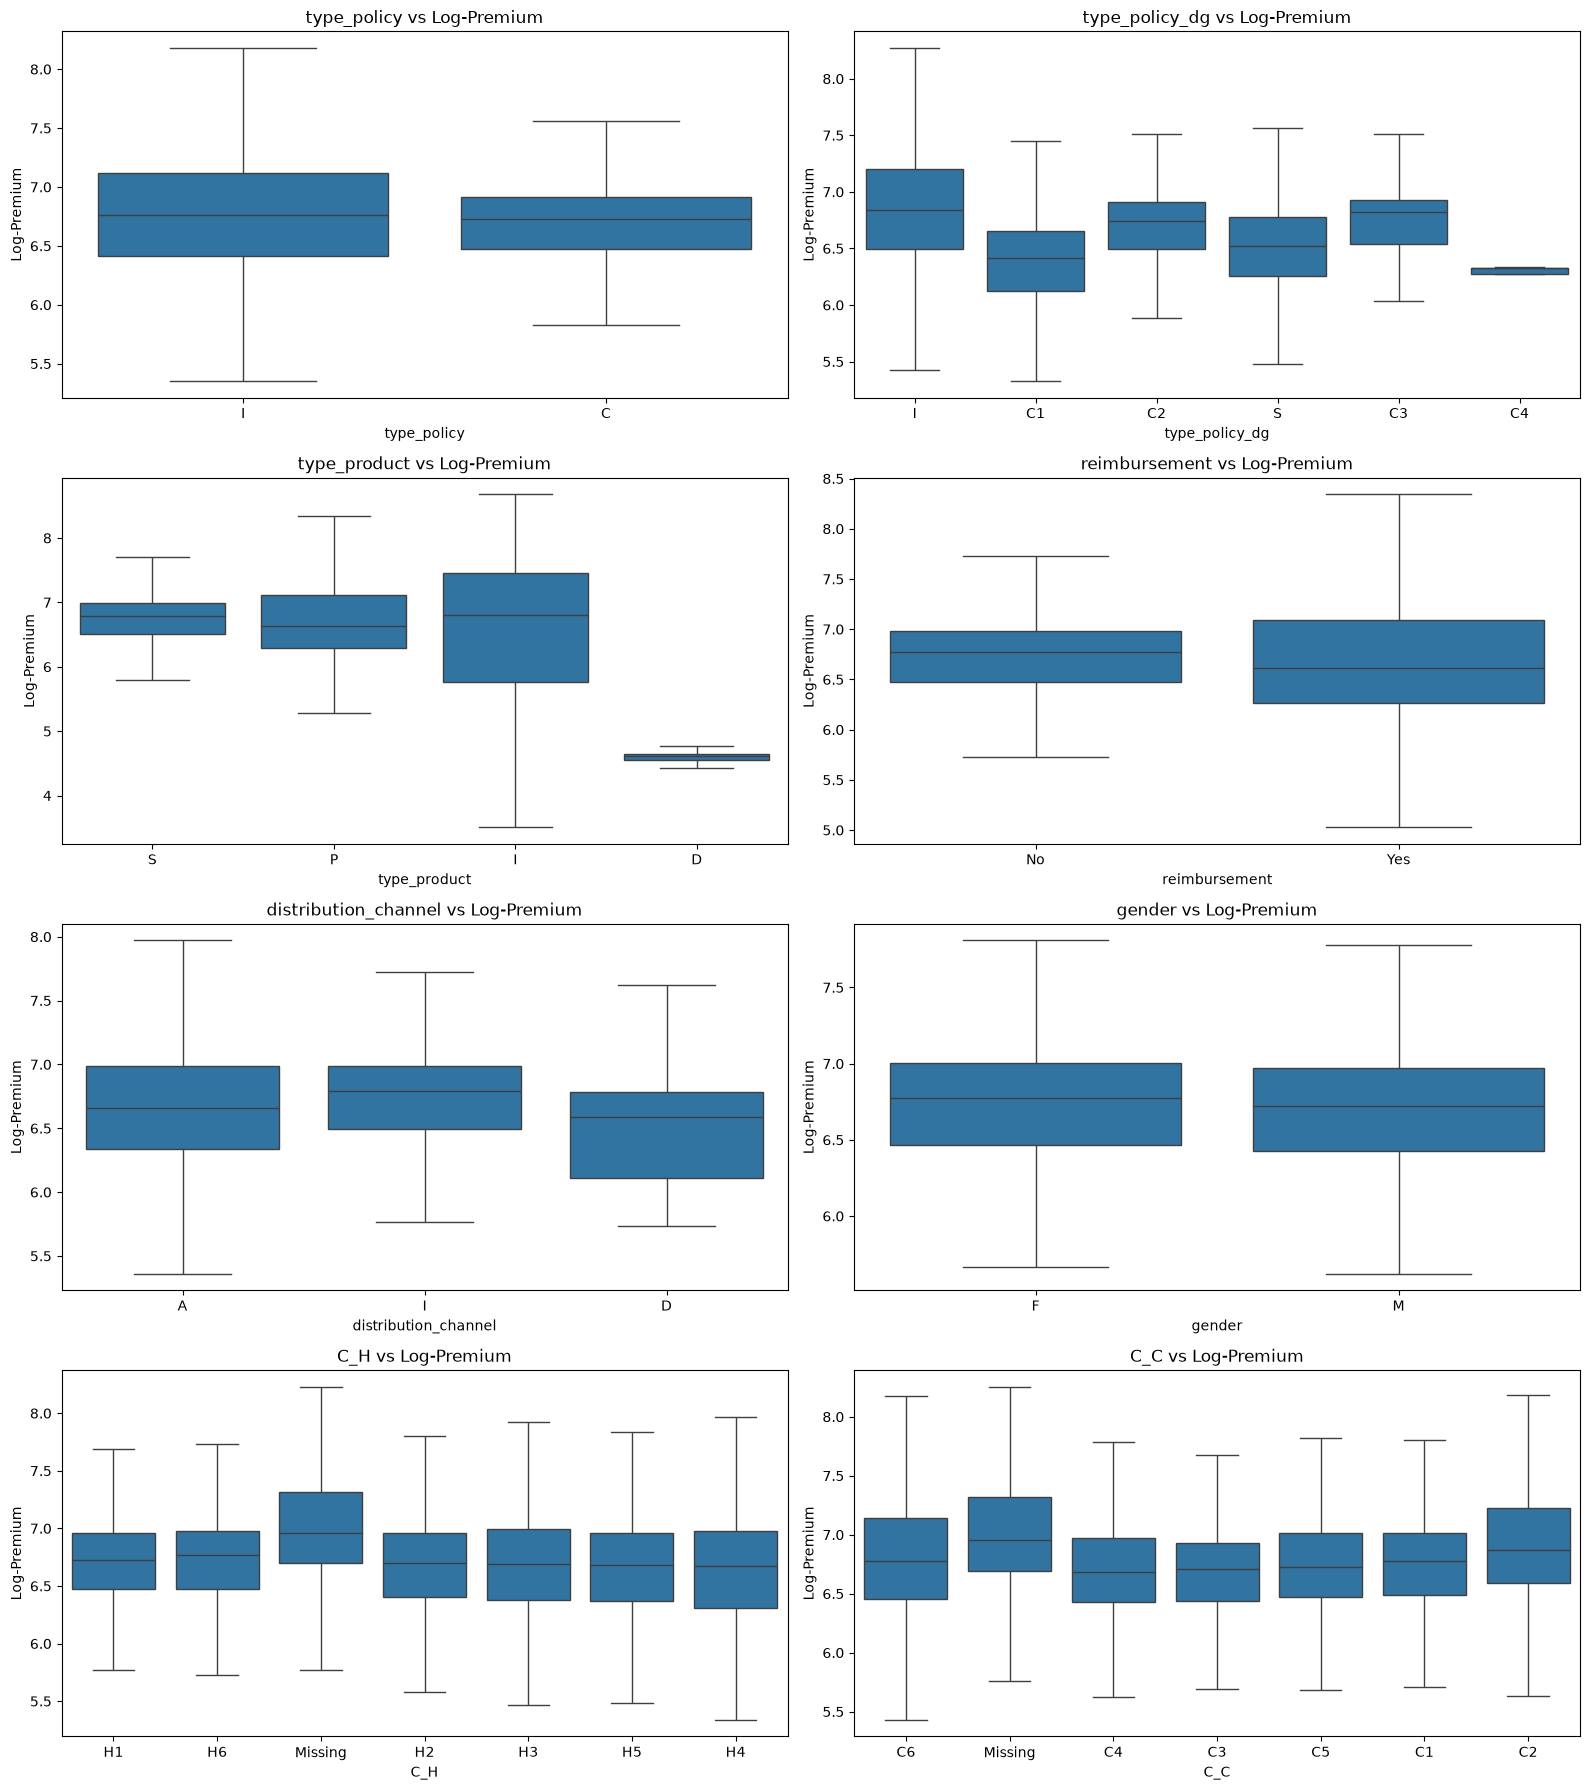

In [75]:
plot_df = df.copy()
plot_df["log_premium"] = np.log(plot_df["premium"])

# Preserve missing values as a separate category
for col in categorical_features:
    plot_df[col] = plot_df[col].astype("object").fillna("Missing")

ncols = 2
nrows = math.ceil(len(categorical_features) / ncols)

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(16, nrows * 4.5)
)

axes = axes.flatten()

for i, col in enumerate(categorical_features):

    sns.boxplot(
        data=plot_df,
        x=col,
        y="log_premium",
        showfliers=False,
        ax=axes[i]
    )

    axes[i].set_title(f"{col} vs Log-Premium")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Log-Premium")

plt.tight_layout()
plt.show()

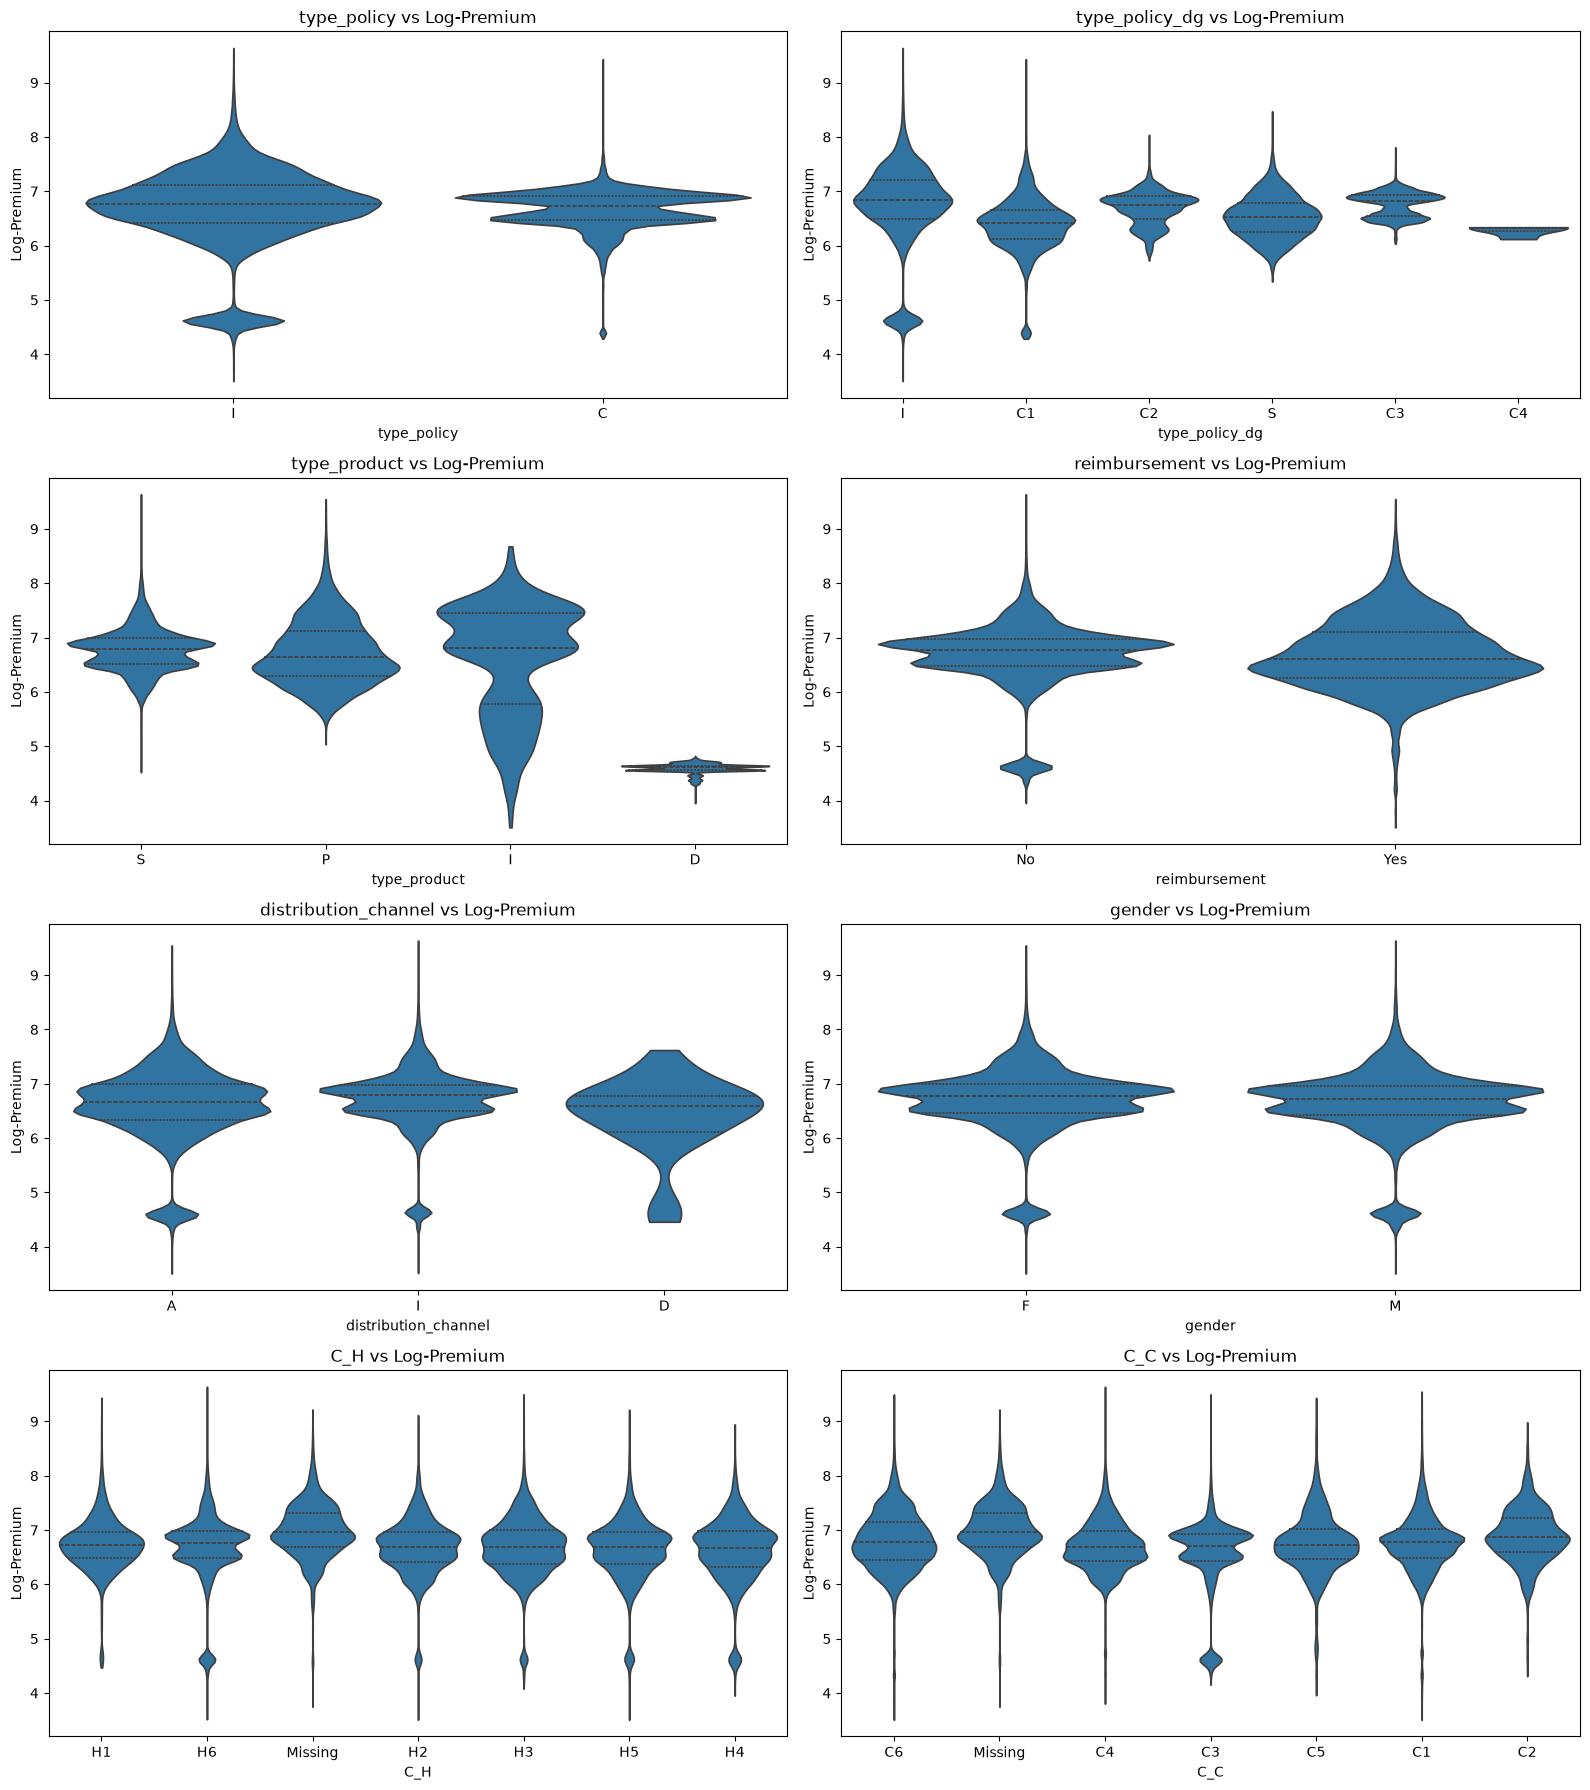

In [76]:
fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(16, nrows * 4.5)
)

axes = axes.flatten()

for i, col in enumerate(categorical_features):

    sns.violinplot(
        data=plot_df,
        x=col,
        y="log_premium",
        inner="quartile",
        cut=0,
        density_norm="width",
        ax=axes[i]
    )

    axes[i].set_title(f"{col} vs Log-Premium")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Log-Premium")

plt.tight_layout()
plt.show()

## Multivariate Analysis And feature redundancy 

In [77]:


# 1. Select numerical predictors
exclude_cols = [
    "ID", "ID_policy", "ID_insured", "period",
    "premium", "log_premium", "previous_premium"
]

numerical_features = [
    col for col in df.select_dtypes(include="number").columns
    if col not in exclude_cols + categorical_features
]

# 2. Calculate correlations
pearson_corr = df[numerical_features].corr(method="pearson")
spearman_corr = df[numerical_features].corr(method="spearman")


# Extract unique predictor pairs (excluding diagonal)
i, j = np.triu_indices(len(numerical_features), k=1)

pairs = pd.DataFrame({
    "Feature_1": np.array(numerical_features)[i],
    "Feature_2": np.array(numerical_features)[j],
    "Pearson": pearson_corr.to_numpy()[i, j],
    "Spearman": spearman_corr.to_numpy()[i, j]
})

pairs["Max_Abs_Correlation"] = pairs[
    ["Pearson", "Spearman"]
].abs().max(axis=1)

pairs = pairs.sort_values(
    "Max_Abs_Correlation", ascending=False
).reset_index(drop=True)

# Top 20 strongest correlations
display(pairs.head(20))

# Strong redundancy candidates
display(pairs[pairs["Max_Abs_Correlation"] >= 0.80])


,Feature_1,Feature_2,Pearson,Spearman,Max_Abs_Correlation
0,C_IE_P,C_GE_P,0.912517,0.999138,0.999138
1,year_effect_policy,seniority_policy,-0.998299,-0.995051,0.998299
2,year_effect_insured,seniority_insured,-0.998033,-0.994864,0.998033
3,C_IE_S,C_GE_S,0.924363,0.996012,0.996012
4,C_GI,C_II,0.848640,0.995768,0.995768
5,C_IE_T,C_GE_T,0.855550,0.994990,0.994990
6,year_lapse_insured,year_lapse_policy,0.986966,0.986966,0.986966
7,C_IE_S,C_IE_T,-0.964888,-0.969728,0.969728
8,year_effect_insured,year_effect_policy,0.953168,0.967576,0.967576
9,seniority_insured,seniority_policy,0.953007,0.967310,0.967310


,Feature_1,Feature_2,Pearson,Spearman,Max_Abs_Correlation
0,C_IE_P,C_GE_P,0.912517,0.999138,0.999138
1,year_effect_policy,seniority_policy,-0.998299,-0.995051,0.998299
2,year_effect_insured,seniority_insured,-0.998033,-0.994864,0.998033
3,C_IE_S,C_GE_S,0.924363,0.996012,0.996012
4,C_GI,C_II,0.848640,0.995768,0.995768
5,C_IE_T,C_GE_T,0.855550,0.994990,0.994990
6,year_lapse_insured,year_lapse_policy,0.986966,0.986966,0.986966
7,C_IE_S,C_IE_T,-0.964888,-0.969728,0.969728
8,year_effect_insured,year_effect_policy,0.953168,0.967576,0.967576
9,seniority_insured,seniority_policy,0.953007,0.967310,0.967310


In [78]:

# Broad policy type for each detailed policy category
display(pd.crosstab(df["type_policy_dg"], df["type_policy"]))

# Reimbursement distribution within each product type
display(pd.crosstab(df["type_product"], df["reimbursement"]))

# Number of distinct broad policy types per detailed category
display(df.groupby("type_policy_dg")["type_policy"].nunique())


type_policy,C,I
type_policy_dg,,
C1,15230,0
C2,3625,0
C3,45205,0
C4,4,0
I,0,77180
S,0,21385


reimbursement,No,Yes
type_product,,
D,7108,0
I,1365,932
P,0,23523
S,129701,0


type_policy_dg
C1    1
C2    1
C3    1
C4    1
I     1
S     1
Name: type_policy, dtype: int64

## Outlier Detection and Analysis

In [79]:

numerical_predictors = [
    "age", "seniority_insured", "seniority_policy",
    "exposure_time", "n_insured_pc", "n_insured_mun",
    "n_insured_prov", "IICIMUN", "IICIPROV",
    "C_GI", "C_II", "C_IE_P", "C_IE_S", "C_IE_T",
    "C_GE_P", "C_GE_S", "C_GE_T"
]


In [80]:

extreme_results = []

for col in numerical_predictors:
    s = df[col].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1

    if iqr == 0:
        continue

    lower = q1 - 3 * iqr
    upper = q3 + 3 * iqr
    extreme = (s < lower) | (s > upper)

    extreme_results.append({
        "Feature": col,
        "Extreme_Count": extreme.sum(),
        "Extreme_Percentage": round(extreme.mean() * 100, 2),
        "Minimum": s.min(),
        "Maximum": s.max(),
        "Lower_Bound": lower,
        "Upper_Bound": upper
    })

extreme_summary = pd.DataFrame(extreme_results).sort_values(
    "Extreme_Percentage", ascending=False
)

display(extreme_summary)


,Feature,Extreme_Count,Extreme_Percentage,Minimum,Maximum,Lower_Bound,Upper_Bound
8,C_GI,3802,2.46,1.00,100.00,18.00,158.00
15,C_GE_T,2891,1.87,1.00,100.00,23.00,156.00
3,n_insured_pc,1338,0.82,1.00,2518.00,-1049.00,1513.00
6,IICIMUN,406,0.26,0.01,263.16,-25.90,38.85
13,C_GE_P,382,0.25,1.00,100.00,-60.00,94.00
2,seniority_policy,293,0.18,1.00,87.00,-48.00,78.00
1,seniority_insured,140,0.09,1.00,86.00,-49.00,77.00
0,age,0,0.00,0.00,99.00,-66.00,165.00
7,IICIPROV,0,0.00,0.01,10.49,-10.29,17.01
5,n_insured_prov,0,0.00,4.00,29465.00,-71302.00,102998.00


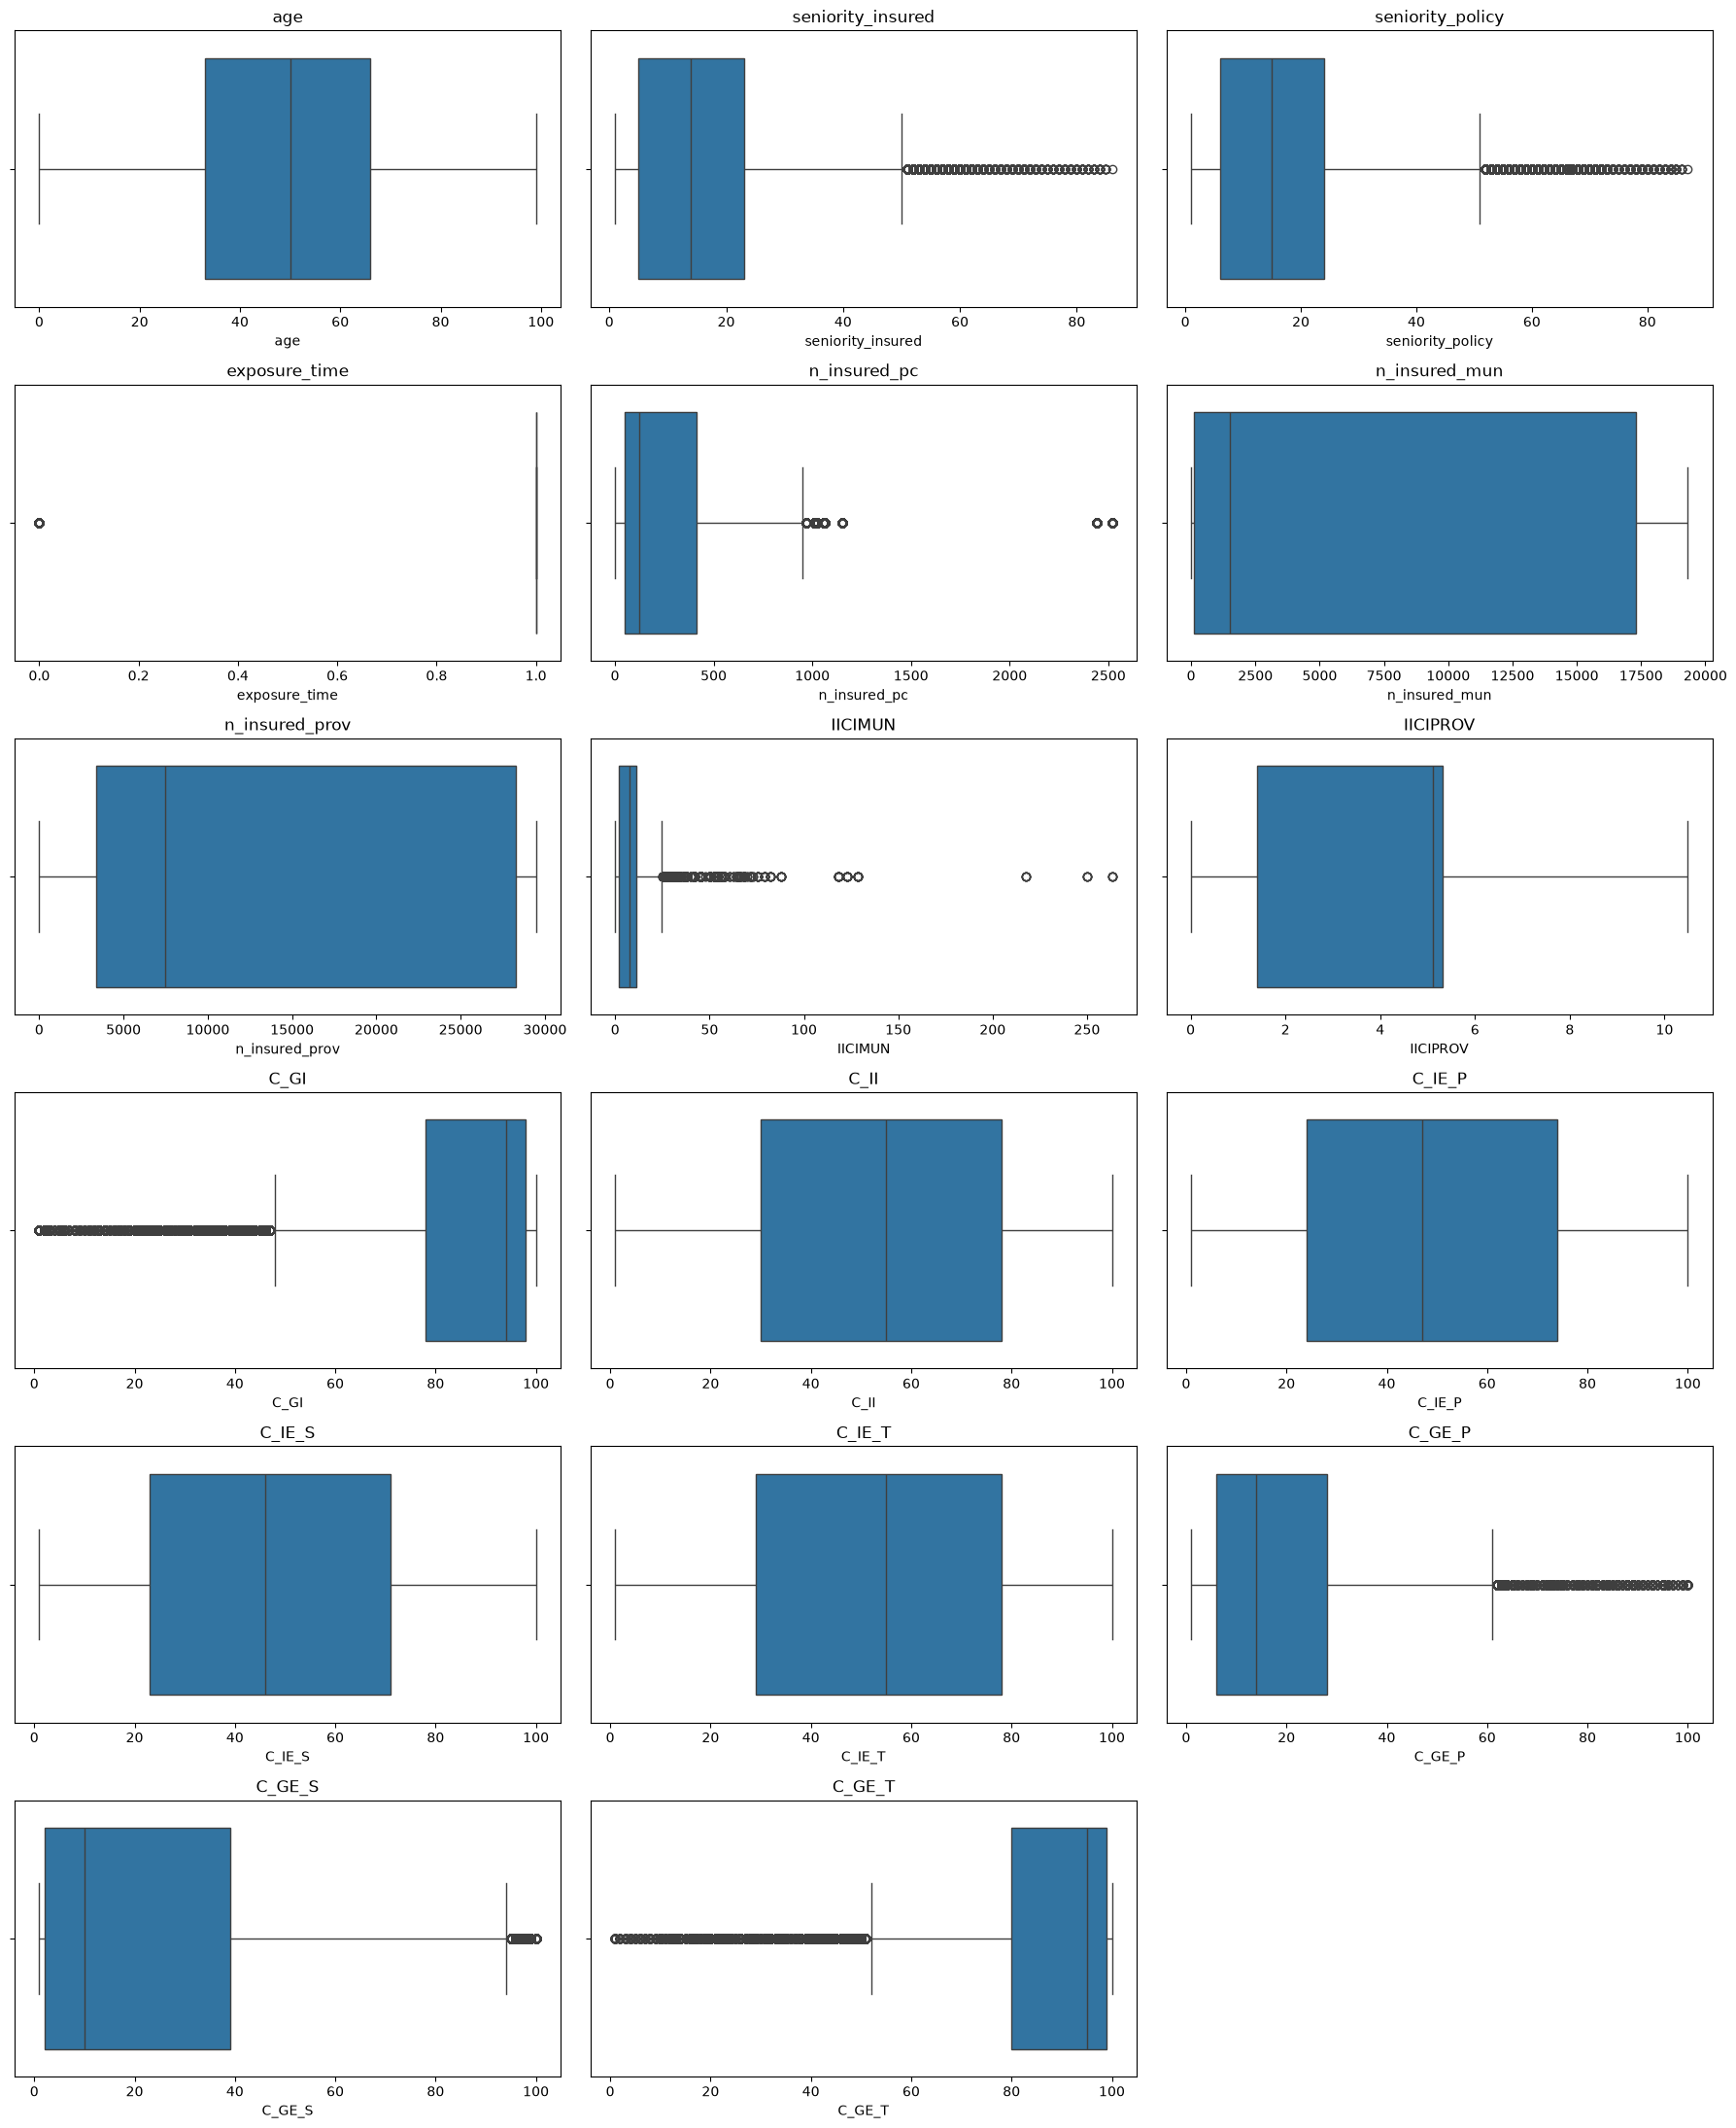

In [81]:

fig, axes = plt.subplots(6, 3, figsize=(18, 22))

for ax, col in zip(axes.flat, numerical_predictors):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(col)

for ax in axes.flat[len(numerical_predictors):]:
    ax.axis("off")

plt.tight_layout()
plt.show()


In [82]:
df['type_policy_dg'].value_counts()

type_policy_dg
I     77180
C3    45205
S     21385
C1    15230
C2     3625
C4        4
Name: count, dtype: int64

In [85]:
# Save the current DataFrame, including EDA changes.
output_path = r"C:\Users\rajab\Desktop\ML-Health-Insurance\ML-Health-Insurance\main\cleaned.csv"

df.to_csv(output_path, index=False)

print("Saved to:", output_path)
print("Saved dataset shape:", df.shape)

Saved to: C:\Users\rajab\Desktop\ML-Health-Insurance\ML-Health-Insurance\main\cleaned.csv
Saved dataset shape: (162629, 42)
